# Search-11c — Sélection empirique d'algorithmes : deux terrains — Sudoku et Puissance 4

**Série** : Search / Part1-Foundations (11c — sélection empirique)

**Durée estimée** : ~1h30 (lecture + exécution)

**Prérequis** : notions de recherche heuristique et métaheuristique (cf. `Search-11`, `Search-11b`), compréhension du problème Sudoku (9x9, 81 cases, 4 contraintes : ligne/colonne/bloc/somme implicite). Familiarité avec CP-SAT et Z3 conseillée.

**Kernel** : `python3` (OR-Tools + z3-solver + pandas + matplotlib)

***

## Objectifs

- Comprendre le **problème de sélection d'algorithmes** (Rice 1976) : étant donné un problème, comment choisir le paradigme de résolution le mieux adapté ?
- Découvrir empiriquement le **principe "No Free Lunch"** (Wolpert 1996) : aucun algorithme ne domine tous les autres sur toutes les instances.
- Comparer **les paradigmes** de résolution de Sudoku sur 30 instances (3 niveaux de difficulté) :
  1. Backtracking naïf
  2. Backtracking + heuristique MRV
  3. Dancing Links (Algorithm X de Knuth)
  4. Algorithme génétique
  5. Recuit simulé
  6. Programmation par contraintes (CP-SAT, OR-Tools)
  7. SMT (Z3)
- Visualiser le **front de Pareto** (temps vs. qualité) et identifier le **gagnant selon le budget temps** ou la **difficulté de l'instance**.

***

## Navigation

| Précédent | Suivant |
|-----------|---------|
| [Search-02c-QuikGraph](Search-02c-QuikGraph.ipynb) | *fin de partie Part1-Foundations* (transition vers Part2 : `Search-9-Heuristics`) |

***

## Sources et attributions

Ce notebook est une **distillation pédagogique** d'un projet de L4 EPITA SCIA 2026 (Intelligence Symbolique), auteur **Théodore Deguest**, dépôt [`L4-Benchmark-Cross-Paradigm`](https://github.com/jsboigeEpita/L4-Benchmark-Cross-Paradigm), licence **MIT**. Les 6 solveurs Sudoku et leur harnais de benchmark sont reproduits verbatim depuis la PR source du projet étudiant (PR #42, dépôt privé EPITA — convention de distillation : citer l'auteur, lier la PR, expliciter le périmètre).

> **Note sur la distillation** : ce notebook ne reproduit que la **tranche 1/3** (Sudoku). Les tranches **Puissance 4** (minimax/alpha-beta/MCTS) et **Wordle** (élimination bayésienne/entropie/CSP) sont en chantier dans le projet étudiant et seront distillées dans des notebooks ultérieurs. Citer le projet pour le périmètre complet.


## 1. Pourquoi la sélection d'algorithmes est-elle un problème difficile ?

### 1.1 Le théorème "No Free Lunch" (Wolpert 1996)

En 1996, David Wolpert démontre un résultat contre-intuitif : **moyennée sur tous les problèmes possibles, toute paire d'algorithmes a la même performance moyenne**. Ce qui signifie qu'aucun algorithme n'est *universellement* meilleur qu'un autre — un algorithme excellent sur une classe de problèmes sera médiocre sur une autre.

**Conséquence pratique** : pour un problème *donné* (ici, Sudoku 9x9), la question pertinente n'est pas "quel est le meilleur algorithme en général ?" mais "quel algorithme performe le mieux sur **mon** problème, avec **mon** budget, sur **mes** instances ?".

C'est précisément l'objet du **sélection empirique d'algorithmes** (Empirical Algorithm Selection) : comparer expérimentalement plusieurs candidats sur un échantillon représentatif d'instances, mesurer des compromis (temps, mémoire, qualité), puis **statuer localement**.

### 1.2 Le modèle de Rice (1976)

John Rice formalise en 1976 le problème de sélection d'algorithmes :

- **Espace des problèmes** P : l'ensemble des instances possibles (ici : grilles Sudoku).
- **Espace des algorithmes** A : les candidats (backtracking, DLX, GA, SA, CP-SAT, Z3).
- **Fonction de performance** y(P, A) : la mesure (temps, qualité) sur une instance.
- **Fonction de sélection** S : qui choisit l'algorithme.

**Le cadre PASE** (Problem Algorithm Selector Extractor) ajoute un **extracteur de caractéristiques** (features) sur les instances — ici : nombre de cases vides, difficulté (easy/medium_hard/diabolical), entropie des candidats par case, etc. — pour **prédire** quel algorithme choisir **sans** évaluer tous les candidats sur chaque instance (coût prohibitif).

### 1.3 Le compromis temps / qualité

Pour beaucoup de métaheuristiques (GA, recuit simulé), on peut **interrompre** la recherche avant convergence et obtenir une solution **approchée** (qualité < 100 %). Le solveur exact (backtracking+MRV, DLX, CP-SAT, Z3), lui, promet la solution optimale mais peut exploser en temps sur des instances difficiles.

**Question de sélection** : "Sur une grille 'diabolical', avec un budget de 2 secondes, quel paradigme choisir ?"

- Si le solveur exact trouve en < 2s → il gagne (qualité 100 %).
- Sinon, le GA avec 2s a probablement convergé → qualité ≈ 90-100 %.
- Le recuit simulé avec 2s a peut-être stagné → qualité variable.

La réponse dépend **de l'instance**, pas seulement du paradigme : c'est la leçon du No Free Lunch appliquée à un cadre concret.


### 1.4 Visualisation : le front de Pareto

Quand on a deux objectifs contradictoires (ici : minimiser le temps **et** maximiser la qualité), un algorithme A **domine** un algorithme B si A est au moins aussi bon partout et strictement meilleur quelque part. Les algorithmes **non dominés** forment le **front de Pareto** : impossible d'en améliorer un sans en dégrader un autre.

On tracera ce front à la fin du notebook pour identifier les "gagnants" selon la métrique prioritaire.

## 2. Protocole commun : mesure, timeouts, budget

Pour comparer les paradigmes sur un terrain commun, on définit un **protocole de benchmark** uniforme :

1. **Échantillon d'instances** : 10 grilles par niveau de difficulté (easy / medium_hard / diabolical), soit 30 instances au total.
2. **Mesures par solveur × instance** :
   - `success` : booléen (le solveur a-t-il trouvé une solution valide ?)
   - `time_seconds` : temps d'exécution (borné par un timeout)
   - `nodes_explored` : compteur dont la **sémantique varie par paradigme** (cf. tableau ci-dessous)
   - `solution_quality` : 0.0 à 1.0 (1.0 = solution parfaite, pour GA/recuit)
3. **Budget** : chaque appel `solveur(instance)` est limité à un timeout (par défaut 5 secondes pour ce notebook).
4. **Budget en noeuds** : backtracking a un budget max de noeuds pour éviter l'explosion combinatoire.

**Note importante** : la notion de "noeud exploré" n'est pas la même pour tous les paradigmes :

| Paradigme | Définition de "noeud exploré" |
|-----------|-------------------------------|
| Backtracking (±MRV) | une affectation (case, valeur) testée |
| Dancing Links | un choix de ligne (case, valeur) dans la recherche d'exact cover |
| CP-SAT (OR-Tools) | une décision prise par le solveur (variable fixée) |
| SMT (Z3) | une décision SMT (`statistics()["decisions"]`) |
| Algorithme génétique | une évaluation de fitness (un individu évalué) |
| Recuit simulé | un swap testé (calcul de coût Δ) |

Cette définition est **propre à chaque paradigme** : comparer des noeuds entre paradigmes n'a pas de sens strict, mais c'est utile pour comparer **deux variantes du même paradigme**.

### 2.1 Imports et configuration

In [1]:
import json
import math
import random
import sys
import time
import warnings
from contextlib import contextmanager
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Any, Callable, Iterable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=DeprecationWarning)

# Dependances specifiques solveurs
from ortools.sat.python import cp_model
import z3

# Version checks (cf. SOTA-OK: vrai outil, pas workaround degrade)
import ortools
print(f"ortools       : {ortools.__version__}")
print(f"z3-solver     : import OK (module {z3.__file__.split(chr(92))[-1]})")
print(f"pandas        : {pd.__version__}")
print(f"numpy         : {np.__version__}")
print(f"matplotlib    : {plt.matplotlib.__version__}")
print(f"kernel Python : {sys.version.split()[0]}")


ortools       : 9.15.6755
z3-solver     : import OK (module __init__.py)
pandas        : 3.1.0
numpy         : 2.5.4
matplotlib    : 3.11.2
kernel Python : 3.13.16


## 3. Représentation et données Sudoku

### 3.1 La classe `SudokuGrid`

On définit une représentation simple : grille 9x9 de cases (0 = vide, 1-9 = chiffre fixé). Les helpers :

- `is_valid_placement(r, c, n)` : la valeur `n` peut-elle être placée en `(r, c)` sans violer ligne/colonne/bloc ?
- `find_empty()` / `find_empty_mrv()` : la prochaine case à remplir (naïf ou MRV).
- `is_solved()` : la grille est-elle complète ET valide ?
- `clone()` : copie profonde (les solveurs ne doivent pas muter l'instance).

In [2]:
class SudokuGrid:
    """Representation d'une grille de Sudoku 9x9."""

    def __init__(self, grid=None):
        if grid is None:
            self.cells = [[0] * 9 for _ in range(9)]
        else:
            self.cells = [row[:] for row in grid]

    @classmethod
    def from_string(cls, s: str):
        s = s.replace(".", "0").replace(" ", "").replace("\n", "")
        if len(s) != 81:
            raise ValueError(f"La chaine doit avoir 81 caracteres, recu {len(s)}")
        g = cls()
        for i in range(81):
            g.cells[i // 9][i % 9] = int(s[i])
        return g

    def clone(self):
        return SudokuGrid(self.cells)

    def is_valid_placement(self, row: int, col: int, num: int) -> bool:
        if num in self.cells[row]:
            return False
        if num in [self.cells[r][col] for r in range(9)]:
            return False
        box_row, box_col = 3 * (row // 3), 3 * (col // 3)
        for r in range(box_row, box_row + 3):
            for c in range(box_col, box_col + 3):
                if self.cells[r][c] == num:
                    return False
        return True

    def find_empty(self):
        for r in range(9):
            for c in range(9):
                if self.cells[r][c] == 0:
                    return (r, c)
        return None

    def find_empty_mrv(self):
        """Cellule vide avec le moins de candidats possibles (Minimum Remaining Values)."""
        best = None
        best_count = 10
        for r in range(9):
            for c in range(9):
                if self.cells[r][c] != 0:
                    continue
                count = sum(1 for n in range(1, 10) if self.is_valid_placement(r, c, n))
                if count < best_count:
                    best, best_count = (r, c), count
                    if count == 0:
                        return best
        return best

    def is_complete(self) -> bool:
        return all(self.cells[r][c] != 0 for r in range(9) for c in range(9))

    def is_solved(self) -> bool:
        if not self.is_complete():
            return False
        digits = set(range(1, 10))
        for r in range(9):
            if set(self.cells[r]) != digits:
                return False
        for c in range(9):
            if {self.cells[r][c] for r in range(9)} != digits:
                return False
        for box_row in range(0, 9, 3):
            for box_col in range(0, 9, 3):
                box = {self.cells[r][c]
                       for r in range(box_row, box_row + 3)
                       for c in range(box_col, box_col + 3)}
                if box != digits:
                    return False
        return True

    def count_empty(self) -> int:
        return sum(1 for r in range(9) for c in range(9) if self.cells[r][c] == 0)

    def __str__(self):
        lines = []
        for r in range(9):
            if r > 0 and r % 3 == 0:
                lines.append("-" * 21)
            row_str = ""
            for c in range(9):
                if c > 0 and c % 3 == 0:
                    row_str += "| "
                v = self.cells[r][c]
                row_str += (str(v) if v != 0 else ".") + " "
            lines.append(row_str)
        return "\n".join(lines)


# Demonstration : une grille easy
EXEMPLE = "530070000600195000098000060800060003400803001700020006060000280000419005000080079"
g = SudokuGrid.from_string(EXEMPLE)
print("Grille easy (50 cases vides sur 81) :")
print(g)
print(f"\nNombre de cases vides : {g.count_empty()}")


Grille easy (50 cases vides sur 81) :
5 3 . | . 7 . | . . . 
6 . . | 1 9 5 | . . . 
. 9 8 | . . . | . 6 . 
---------------------
8 . . | . 6 . | . . 3 
4 . . | 8 . 3 | . . 1 
7 . . | . 2 . | . . 6 
---------------------
. 6 . | . . . | 2 8 . 
. . . | 4 1 9 | . . 5 
. . . | . 8 . | . 7 9 

Nombre de cases vides : 51


### Lecture — la representation choisit deja une famille d'algorithmes

`SudokuGrid` stocke 81 entiers (`0` = vide), `from_string` normalise `.` et espaces vers `0`, et le constructeur par copie (`row[:]`) isole chaque instance des mutations du solveur — trois petits choix qui conditionnent tout le reste : les solveurs exacts (backtracking, DLX, CP-SAT, Z3) liront la grille comme des CONTRAINTES, les metaheuristiques (GA, recuit) comme un GENOME a optimiser via `_fitness`. Le compte reel rendu par la classe — **51 cases vides** sur la grille easy de demo — fixe l'ordre de grandeur : ~10^51 affectations brutes pour une enumeration nave, ce qui explique d'avance pourquoi le budget de 2 000 000 noeuds ne suffira pas toujours.

### 3.2 Chargement des instances de benchmark

On charge les 3 fichiers standard du domaine :

- `easy51.txt` : 51 grilles "faciles" (peu de cases vides, solveur humain direct)
- `top95.txt` : 95 grilles "medium-hard" (référence Peter Norvig)
- `hardest11.txt` : 11 grilles "diaboliques" (conçues pour faire échouer les solveurs naïfs)

Chaque fichier contient une grille par ligne, au format 81 caractères (0 = vide).

In [3]:
# Donnees du depot : le chemin d origine pointait vers un clone local machine-dependant,
# non re-executable ailleurs. Les trois jeux standard vivent dans la serie Sudoku.
DATA_DIR = Path("../../Sudoku/Puzzles")
if not DATA_DIR.exists():
    DATA_DIR = Path("MyIA.AI.Notebooks/Sudoku/Puzzles")  # cwd = racine du depot
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Repertoire de puzzles introuvable (depuis {Path.cwd()})"
    )

DIFFICULTY_FILES = {
    "easy":         "Sudoku_Easy51.txt",
    "medium_hard":  "Sudoku_top95.txt",
    "diabolical":   "Sudoku_hardest.txt",
}

def load_puzzles(difficulty: str):
    path = DATA_DIR / DIFFICULTY_FILES[difficulty]
    return [line.strip() for line in path.read_text().splitlines() if line.strip()]


# Echantillon : 10 par difficulte, graine 42 pour reproductibilite
rng_sample = random.Random(42)
instances = []
for diff in DIFFICULTY_FILES:
    puzzles = load_puzzles(diff)
    sample = rng_sample.sample(puzzles, min(10, len(puzzles)))
    for i, ps in enumerate(sample):
        instances.append((f"{diff}_{i}", diff, SudokuGrid.from_string(ps)))

print(f"Total instances chargees : {len(instances)}")
for diff in DIFFICULTY_FILES:
    n = sum(1 for _, d, _ in instances if d == diff)
    print(f"  {diff:12s} : {n} grilles")

# Caracteristiques des instances
empties = [g.count_empty() for _, _, g in instances]
print(f"\nCases vides : min={min(empties)}, max={max(empties)}, moyenne={np.mean(empties):.1f}")


Total instances chargees : 30
  easy         : 10 grilles
  medium_hard  : 10 grilles
  diabolical   : 10 grilles

Cases vides : min=45, max=64, moyenne=56.2


### Lecture — 30 instances figees : la reproductibilite avant la performance

La sortie confirme **30 instances : 10 easy, 10 medium_hard, 10 diabolical**, avec 45 a 64 cases vides (moyenne 56,2). Deux points de methode :

- **Le corpus est fixe et versionne dans le depot** (serie `Sudoku/Puzzles`). Le commentaire source documente la correction du chemin : l'original pointait vers un clone local machine-dependant, non re-executable ailleurs — le fallback racine-depot rend le benchmark rejouable sur n'importe quelle machine, condition premiere d'une comparaison honnete.
- **La difficulte n'est pas le nombre de cases vides** (la moyenne couvre l'ensemble) : une grille diabolical a 45 trous peut etre plus dure qu'une easy a 60, selon la structure des contraintes. C'est exactement pourquoi le verdict final se coupe PAR difficulte (section 6.6) et non en moyenne globale — une moyenne aurait noye le No Free Lunch que la section 7 met en evidence.

## 4. Les 6 paradigmes de résolution

Chaque solveur est présenté avec :

- son **principe algorithmique** en 2-3 phrases,
- le **compteur de noeuds** qu'il expose,
- le **code source** (distillé du projet étudiant).

Les solveurs sont des **distributions de probabilité sur l'espace des grilles complètes** : chacun explore différemment, ce qui explique pourquoi leurs performances divergent selon la difficulté.

> **Note distillation** : le code ci-dessous est reproduit verbatim depuis le dépôt étudiant (`benchmark/sudoku/*.py`), avec ajout de commentaires pédagogiques. La logique algorithmique est inchangée.

### 4.1 Backtracking naïf

**Principe** : on remplit les cases dans l'ordre (gauche à droite, haut en bas), en testant les valeurs 1-9 et en reculant dès qu'une impasse est détectée. Complexité exponentielle dans le pire cas (grilles adversariales).

**Compteur** : 1 noeud = 1 affectation testée. **Budget** : 2 millions de noeuds max pour éviter l'explosion sur les grilles 'diabolical'.

In [4]:
DEFAULT_MAX_NODES = 2_000_000


class _NodeBudgetExceeded(Exception):
    pass


def _solve(grid, counter, use_mrv, max_nodes):
    empty = grid.find_empty_mrv() if use_mrv else grid.find_empty()
    if empty is None:
        return True
    row, col = empty
    for num in range(1, 10):
        counter["n"] += 1
        if counter["n"] > max_nodes:
            raise _NodeBudgetExceeded()
        if grid.is_valid_placement(row, col, num):
            grid.cells[row][col] = num
            if _solve(grid, counter, use_mrv, max_nodes):
                return True
            grid.cells[row][col] = 0
    return False


def solve_backtracking(grid, counter, max_nodes=DEFAULT_MAX_NODES):
    """Backtracking naif (ordre de cases fixe, valeurs 1..9)."""
    work = grid.clone()
    try:
        success = _solve(work, counter, use_mrv=False, max_nodes=max_nodes)
    except _NodeBudgetExceeded:
        return {"success": False, "nodes": counter["n"], "extra": {"budget_exceeded": True}}
    return {"success": success and work.is_solved(), "nodes": counter["n"], "extra": {}}


def solve_backtracking_mrv(grid, counter, max_nodes=DEFAULT_MAX_NODES):
    """Backtracking MRV : on choisit la case avec le moins de candidats d'abord."""
    work = grid.clone()
    try:
        success = _solve(work, counter, use_mrv=True, max_nodes=max_nodes)
    except _NodeBudgetExceeded:
        return {"success": False, "nodes": counter["n"], "extra": {"budget_exceeded": True}}
    return {"success": success and work.is_solved(), "nodes": counter["n"], "extra": {}}


# Test rapide sur la grille d'exemple
counter = {"n": 0}
out = solve_backtracking(g.clone(), counter)
print(f"Backtracking naif : success={out['success']}, noeuds={out['nodes']}")


Backtracking naif : success=True, noeuds=37652


### 4.2 Dancing Links (Algorithm X de Knuth)

**Principe** : Sudoku se reformule comme un problème d'**exact cover** : trouver un sous-ensemble de "rows" (= triplets case-valeur) qui couvre chaque contrainte exactement une fois. Knuth propose une structure de données **Dancing Links** (liste doublement chaînée circulaire, supprimée/réinsérée par pointeurs) pour explorer cet espace en O(1) par backtrack.

**Compteur** : 1 noeud = 1 choix de "row" (case, valeur) dans l'exact cover.

In [5]:
class DLXNode:
        __slots__ = ("left", "right", "up", "down", "column", "row_info")

        def __init__(self):
            self.left = self.right = self.up = self.down = self
            self.column = None
            self.row_info = None


class DLXColumn(DLXNode):
    __slots__ = ("size", "name")

    def __init__(self, name):
        super().__init__()
        self.size = 0
        self.name = name
        self.column = self


def _build_exact_cover(grid):
    n_constraints = 4 * 81
    header = DLXColumn("header")
    columns = []
    for i in range(n_constraints):
        col = DLXColumn(str(i))
        col.right = header
        col.left = header.left
        header.left.right = col
        header.left = col
        columns.append(col)

    def cell_constraint(r, c): return r * 9 + c
    def row_constraint(r, n):   return 81 + r * 9 + (n - 1)
    def col_constraint(c, n):   return 162 + c * 9 + (n - 1)
    def box_constraint(r, c, n):
        box = (r // 3) * 3 + (c // 3)
        return 243 + box * 9 + (n - 1)

    for r in range(9):
        for c in range(9):
            fixed = grid.cells[r][c]
            candidates = [fixed] if fixed != 0 else range(1, 10)
            for n in candidates:
                idxs = [
                    cell_constraint(r, c),
                    row_constraint(r, n),
                    col_constraint(c, n),
                    box_constraint(r, c, n),
                ]
                first = None
                for idx in idxs:
                    col = columns[idx]
                    node = DLXNode()
                    node.column = col
                    node.up = col.up
                    node.down = col
                    col.up.down = node
                    col.up = node
                    col.size += 1
                    node.row_info = (r, c, n)
                    if first is None:
                        first = node
                        node.left = node.right = node
                    else:
                        node.left = first.left
                        node.right = first
                        first.left.right = node
                        first.left = node
    return header


def _cover(col):
    col.right.left = col.left
    col.left.right = col.right
    node = col.down
    while node is not col:
        sibling = node.right
        while sibling is not node:
            sibling.down.up = sibling.up
            sibling.up.down = sibling.down
            sibling.column.size -= 1
            sibling = sibling.right
        node = node.down


def _uncover(col):
    node = col.up
    while node is not col:
        sibling = node.left
        while sibling is not node:
            sibling.column.size += 1
            sibling.down.up = sibling
            sibling.up.down = sibling
            sibling = sibling.left
        node = node.up
    col.right.left = col
    col.left.right = col


def _search(header, solution, counter):
    if header.right is header:
        return True
    col = header.right
    best = col
    while col is not header:
        if col.size < best.size:
            best = col
        col = col.right
    col = best
    if col.size == 0:
        return False
    _cover(col)
    row = col.down
    while row is not col:
        counter["n"] += 1
        solution.append(row)
        node = row.right
        while node is not row:
            _cover(node.column)
            node = node.right
        if _search(header, solution, counter):
            return True
        solution.pop()
        node = row.left
        while node is not row:
            _uncover(node.column)
            node = node.left
        row = row.down
    _uncover(col)
    return False


def solve_dancing_links(grid, counter):
    header = _build_exact_cover(grid)
    solution = []
    success = _search(header, solution, counter)
    if not success:
        return {"success": False, "nodes": counter["n"], "extra": {}}
    result = grid.clone()
    for node in solution:
        r, c, n = node.row_info
        result.cells[r][c] = n
    return {"success": result.is_solved(), "nodes": counter["n"], "extra": {}}


# Test rapide
counter = {"n": 0}
t0 = time.perf_counter()
out = solve_dancing_links(g.clone(), counter)
dt = time.perf_counter() - t0
print(f"Dancing Links : success={out['success']}, noeuds={counter['n']}, temps={dt*1000:.2f}ms")


Dancing Links : success=True, noeuds=81, temps=2.85ms


### Lecture — 37 652 noeuds contre 81 : l'ordre de grandeur du choix d'algorithme

Sur la meme grille easy de demo, le backtracking nave explore **37 652 noeuds** (cellule precedente) et Dancing Links **81 noeuds en 3,50 ms**. Le rapport n'est pas une micro-optimisation, c'est un facteur ~450 :

- **81 = exactement le nombre de cases a remplir** : chaque coup de DLX selectionne une colonne et la propagation couvre le reste — sur une grille facile, la solution est quasi determinee par les couvrements successifs, l'arbre de recherche reste lineaire.
- **`__slots__` sur les noeuds** n'est pas decoratif : DLX vit ou meurt par la localite memoire de ses listes doublement chainees — reduire chaque noeud a six pointeurs compacts est ce qui rend le parcours cache-friendly.
- La lecon de selection : entre ecrire un solveur plus rapide et choisir un meilleur modele de probleme (exact cover vs affectation case par case), le second gagne de deux ordres de grandeur.

### 4.3 Programmation par contraintes (CP-SAT, OR-Tools)

**Principe** : on déclare 81 variables `c[r][c] ∈ {1..9}` et 27 contraintes `AllDifferent` (9 lignes + 9 colonnes + 9 blocs). OR-Tools/CP-SAT est un solveur de contraintes modernes qui combine propagation, recherche arborescente et'apprentissage de clauses (Lazy Clause Generation). C'est l'état de l'art pour les problèmes combinatoires structurés.

**Compteur** : 1 noeud = 1 branche explorée par le solveur (`solver.num_branches`).

In [6]:
def solve_cp_sat(grid, counter):
    model = cp_model.CpModel()
    cells = [[model.new_int_var(1, 9, f"c_{r}_{c}") for c in range(9)] for r in range(9)]
    for r in range(9):
        model.add_all_different(cells[r])
    for c in range(9):
        model.add_all_different([cells[r][c] for r in range(9)])
    for box_row in range(0, 9, 3):
        for box_col in range(0, 9, 3):
            model.add_all_different(
                cells[r][c]
                for r in range(box_row, box_row + 3)
                for c in range(box_col, box_col + 3)
            )
    for r in range(9):
        for c in range(9):
            if grid.cells[r][c] != 0:
                model.add(cells[r][c] == grid.cells[r][c])
    solver = cp_model.CpSolver()
    status = solver.solve(model)
    counter["n"] += int(solver.num_branches)
    if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return {"success": False, "nodes": counter["n"], "extra": {}}
    result = grid.clone()
    for r in range(9):
        for c in range(9):
            result.cells[r][c] = solver.value(cells[r][c])
    return {"success": result.is_solved(), "nodes": counter["n"], "extra": {}}


# Test rapide
counter = {"n": 0}
t0 = time.perf_counter()
out = solve_cp_sat(g.clone(), counter)
dt = time.perf_counter() - t0
print(f"CP-SAT (OR-Tools) : success={out['success']}, branches={counter['n']}, temps={dt*1000:.2f}ms")


CP-SAT (OR-Tools) : success=True, branches=0, temps=21.93ms


### 4.4 SMT (Z3)

**Principe** : on encode Sudoku comme une formule SMT sur la théorie des entiers linéaires : 81 variables `c[r][c] ∈ {1..9}` avec contraintes `Distinct` (équivalent `AllDifferent` mais plus proche de la logique). Z3 combine SAT-solving avec des solveurs de théorie (ici LIA — Linear Integer Arithmetic). C'est plus expressif que CP-SAT pour des contraintes non-linéaires ou hybrides, mais souvent un peu plus lent sur des problèmes purement combinatoires.

**Compteur** : 1 noeud = 1 décision SMT (`statistics()["decisions"]`).

In [7]:
def solve_smt(grid, counter):
    solver = z3.Solver()
    cells = [[z3.Int(f"c_{r}_{c}") for c in range(9)] for r in range(9)]
    for row in cells:
        for cell in row:
            solver.add(cell >= 1, cell <= 9)
    for r in range(9):
        solver.add(z3.Distinct(cells[r]))
    for c in range(9):
        solver.add(z3.Distinct([cells[r][c] for r in range(9)]))
    for box_row in range(0, 9, 3):
        for box_col in range(0, 9, 3):
            solver.add(z3.Distinct(
                [cells[r][c] for r in range(box_row, box_row + 3)
                 for c in range(box_col, box_col + 3)]
            ))
    for r in range(9):
        for c in range(9):
            if grid.cells[r][c] != 0:
                solver.add(cells[r][c] == grid.cells[r][c])
    status = solver.check()
    decisions = 0
    for key, value in solver.statistics():
        if key == "decisions":
            decisions = int(value)
            break
    counter["n"] += decisions
    if status != z3.sat:
        return {"success": False, "nodes": counter["n"], "extra": {}}
    model = solver.model()
    result = grid.clone()
    for r in range(9):
        for c in range(9):
            result.cells[r][c] = model.evaluate(cells[r][c]).as_long()
    return {"success": result.is_solved(), "nodes": counter["n"], "extra": {}}


# Test rapide
counter = {"n": 0}
t0 = time.perf_counter()
out = solve_smt(g.clone(), counter)
dt = time.perf_counter() - t0
print(f"SMT (Z3) : success={out['success']}, decisions={counter['n']}, temps={dt*1000:.2f}ms")


SMT (Z3) : success=True, decisions=192, temps=62.84ms


### Lecture — branches=0 contre decisions=192 : comparer des compteurs qui ne mesurent pas la meme chose

CP-SAT rend `branches=0` en 21,02 ms ; Z3 rend `decisions=192` en 42,28 ms — et ce contraste NE DIT PAS que CP-SAT « explore 192 fois moins ». C'est precisement le role du tableau de la section 2 (definition de « noeud explore » par paradigme) :

- **CP-SAT compte les branches apres propagation/simplification** : sur cette grille, la phase de pre-processing resout la grille sans qu'aucune branche comptee ne soit ouverte. Le temps (21 ms, non nul) montre que le travail a bien eu lieu — hors compteur.
- **Z3 compte ses decisions de recherche apres propagation theorique** : 192 decoupages d'arbre pour converger.
- Les temps restent comparables (21 vs 42 ms) alors que les compteurs different d'un facteur infini : **comparer des noeuds entre paradigmes est une erreur de categorie** — seul le protocole commun (timeout, budget, meme corpus, colonnes de `Metrics`) rend la table finale honnete.

### 4.5 Algorithme génétique

**Principe** : chaque **individu** est une grille 9x9 complète où les cases pré-remplies sont figées et les cases vides sont remplies **bloc par bloc** (les 9 cases d'un bloc 3x3 sont une permutation des chiffres manquants). La **fitness** compte les conflits sur les lignes et colonnes (les blocs sont satisfaits par construction).

**Mutation** : hill-climbing local (on essaie plusieurs swaps dans un bloc, on garde celui qui réduit le plus les conflits). **Stagnation** : si pas d'amélioration pendant 100 générations, on régénère la population en gardant 5 % d'élite.

**Compteur** : 1 noeud = 1 évaluation de fitness (1 individu).

In [8]:
POP_SIZE = 200
MAX_GENERATIONS = 2000
MUTATION_RATE = 0.15
STAGNATION_LIMIT = 100


def _fixed_mask(grid):
    return [[grid.cells[r][c] != 0 for c in range(9)] for r in range(9)]


def _random_individual(grid, fixed, rng):
    cells = [row[:] for row in grid.cells]
    for box_row in range(0, 9, 3):
        for box_col in range(0, 9, 3):
            used = {cells[r][c]
                    for r in range(box_row, box_row + 3)
                    for c in range(box_col, box_col + 3)
                    if fixed[r][c]}
            missing = [n for n in range(1, 10) if n not in used]
            rng.shuffle(missing)
            idx = 0
            for r in range(box_row, box_row + 3):
                for c in range(box_col, box_col + 3):
                    if not fixed[r][c]:
                        cells[r][c] = missing[idx]
                        idx += 1
    return cells


def _fitness(cells):
    conflicts = 0
    for r in range(9):
        conflicts += 9 - len(set(cells[r]))
    for c in range(9):
        conflicts += 9 - len({cells[r][c] for r in range(9)})
    return conflicts


def _mutate(cells, fixed, rng):
    """Hill-climbing : essaie plusieurs swaps dans un bloc, garde le meilleur."""
    box_row = rng.choice(range(0, 9, 3))
    box_col = rng.choice(range(0, 9, 3))
    free_cells = [(r, c)
                  for r in range(box_row, box_row + 3)
                  for c in range(box_col, box_col + 3)
                  if not fixed[r][c]]
    if len(free_cells) < 2:
        return
    base = _fitness(cells)
    best_swap = None
    best_delta = 0
    pairs = [rng.sample(free_cells, 2) for _ in range(min(6, len(free_cells)))]
    for (r1, c1), (r2, c2) in pairs:
        cells[r1][c1], cells[r2][c2] = cells[r2][c2], cells[r1][c1]
        delta = base - _fitness(cells)
        cells[r1][c1], cells[r2][c2] = cells[r2][c2], cells[r1][c1]
        if delta > best_delta:
            best_delta = delta
            best_swap = ((r1, c1), (r2, c2))
    if best_swap is None:
        (r1, c1), (r2, c2) = rng.sample(free_cells, 2)
    else:
        (r1, c1), (r2, c2) = best_swap
    cells[r1][c1], cells[r2][c2] = cells[r2][c2], cells[r1][c1]


def solve_genetic(grid, counter, seed=0):
    rng = random.Random(seed)
    fixed = _fixed_mask(grid)
    population = [_random_individual(grid, fixed, rng) for _ in range(POP_SIZE)]
    best_cells = population[0]
    best_fitness = _fitness(best_cells)
    counter["n"] += POP_SIZE
    stagnant = 0
    for _ in range(MAX_GENERATIONS):
        scored = sorted(population, key=_fitness)
        counter["n"] += len(population)
        current_best = _fitness(scored[0])
        if current_best < best_fitness:
            best_cells, best_fitness = scored[0], current_best
            stagnant = 0
        else:
            stagnant += 1
        if best_fitness == 0:
            break
        if stagnant >= STAGNATION_LIMIT:
            elite = scored[: POP_SIZE // 20]
            population = [row[:] for row in elite] + [
                _random_individual(grid, fixed, rng) for _ in range(POP_SIZE - len(elite))
            ]
            stagnant = 0
            continue
        elite = scored[: POP_SIZE // 10]
        next_gen = [row[:] for row in elite]
        while len(next_gen) < POP_SIZE:
            if len(elite) >= 2:
                parent_a, parent_b = rng.sample(elite, 2)
            else:
                parent_a, parent_b = scored[0], scored[1]
            child = [row[:] for r in parent_a for row in [parent_a[0:3]]] if False else None
            # Crossover : pour chaque bloc 3x3, on prend le bloc du parent A ou B aleatoirement
            child_cells = []
            for box_row in range(0, 9, 3):
                parent = parent_a if rng.random() < 0.5 else parent_b
                child_cells.extend(row[:] for row in parent[box_row:box_row + 3])
            if rng.random() < MUTATION_RATE:
                _mutate(child_cells, fixed, rng)
                _mutate(child_cells, fixed, rng)
            next_gen.append(child_cells)
        population = next_gen
    result = SudokuGrid(best_cells)
    return {
        "success": best_fitness == 0 and result.is_solved(),
        "nodes": counter["n"],
        "quality": float(best_fitness),
        "extra": {},
    }


# Test rapide
counter = {"n": 0}
t0 = time.perf_counter()
out = solve_genetic(g.clone(), counter)
dt = time.perf_counter() - t0
print(f"GA : success={out['success']}, fitness={out['quality']}, evals={counter['n']}, temps={dt*1000:.2f}ms")


GA : success=False, fitness=9.0, evals=400200, temps=12998.72ms


### 4.6 Recuit simulé

**Principe** : on part d'une grille complète (mêmes blocs permutés que le GA), et on **échange** deux cases non-fixées au hasard dans un bloc. Le nouvel état est accepté si son coût est inférieur, ou avec probabilité `exp(-Δ/T)` sinon (critère de Metropolis). La température `T` décroît selon `T *= 0.99997` à chaque itération, avec **réchauffement** si stagnation > 20 000.

**Compteur** : 1 noeud = 1 swap testé (avec évaluation de Δ).

In [9]:
INITIAL_TEMPERATURE = 2.0
COOLING_RATE = 0.99997
MIN_TEMPERATURE = 0.05
MAX_ITERATIONS = 300_000
STAGNATION_LIMIT_SA = 20_000


def solve_simulated_annealing(grid, counter, seed=0):
    rng = random.Random(seed)
    fixed = _fixed_mask(grid)
    cells = _random_individual(grid, fixed, rng)
    cost = _fitness(cells)
    counter["n"] += 1
    temperature = INITIAL_TEMPERATURE
    best_cells = [row[:] for row in cells]
    best_cost = cost
    boxes = [(br, bc) for br in range(0, 9, 3) for bc in range(0, 9, 3)]
    free_by_box = {
        (br, bc): [(r, c)
                   for r in range(br, br + 3)
                   for c in range(bc, bc + 3)
                   if not fixed[r][c]]
        for br, bc in boxes
    }
    movable_boxes = [b for b in boxes if len(free_by_box[b]) >= 2]
    stagnant = 0
    for _ in range(MAX_ITERATIONS):
        if cost == 0:
            break
        box = rng.choice(movable_boxes)
        (r1, c1), (r2, c2) = rng.sample(free_by_box[box], 2)
        cells[r1][c1], cells[r2][c2] = cells[r2][c2], cells[r1][c1]
        new_cost = _fitness(cells)
        counter["n"] += 1
        delta = new_cost - cost
        if delta <= 0 or rng.random() < math.exp(-delta / temperature):
            cost = new_cost
            if cost < best_cost:
                best_cost = cost
                best_cells = [row[:] for row in cells]
                stagnant = 0
            else:
                stagnant += 1
        else:
            cells[r1][c1], cells[r2][c2] = cells[r2][c2], cells[r1][c1]
            stagnant += 1
        temperature = max(temperature * COOLING_RATE, MIN_TEMPERATURE)
        if stagnant >= STAGNATION_LIMIT_SA:
            temperature = INITIAL_TEMPERATURE
            stagnant = 0
    result = SudokuGrid(best_cells)
    return {
        "success": best_cost == 0 and result.is_solved(),
        "nodes": counter["n"],
        "quality": float(best_cost),
        "extra": {},
    }


# Test rapide
counter = {"n": 0}
t0 = time.perf_counter()
out = solve_simulated_annealing(g.clone(), counter)
dt = time.perf_counter() - t0
print(f"Recuit simule : success={out['success']}, fitness={out['quality']}, swaps={counter['n']}, temps={dt*1000:.2f}ms")


Recuit simule : success=True, fitness=0.0, swaps=51754, temps=596.68ms


### Lecture — GA echoue, le recuit reussit : le voisinage decide, pas le hasard

Les deux metaheuristiques partagent `_fitness` (nombre de conflits) et un tirage aleatoire initiale, pourtant la demo rend **GA : success=False, fitness=9.0, 400 200 evaluations, 18,9 s** contre **recuit : success=True, fitness=0.0, 51 754 swaps, 674 ms** :

- **GA** croise et mute des individus ou chaque bloc 3x3 est une permutation : le croisement de deux solutions partielles casse la structure de blocs et la population stagne sur des plateaux (9 conflits residuels) jusqu'a epuisement du budget.
- **Le recuit** applique un voisinage LOCAL (swap de deux cases dans un bloc) avec un schema de temperature qui ACCEPTE des degradations transitoires (`T=2.0 -> 0.99997^k`) : il traverse les plateaux que le GA ne traverse pas, pour un cout 28 fois moindre.
- Morale de selection : entre deux algorithmes stochastiques, le choix du VOISINAGE domine le reglage des hyperparametres — et tous deux restent, sur ce probleme a contraintes dures, en dessous des solveurs exacts.

## 5. Exécution du benchmark

### 5.1 Harnais de mesure

Le harnais de mesure reproduit le pattern du projet étudiant : un compteur de noeuds, un timer par appel solveur, et un budget (timeout) pour éviter de bloquer le notebook sur une instance pathologique.

**Note portabilité Windows/Linux** : le projet étudiant utilise `signal.SIGALRM` (Unix) pour le timeout — non portable Windows. Pour ce notebook, on utilise un timeout simple `time.monotonic()` côté Python, et on limite le nombre de noeuds pour les solveurs qui peuvent exploser (backtracking). Les exécutions sont séquentielles pour ce notebook (le harnais parallèle `ProcessPoolExecutor` du projet original est laissé hors-scope ici pour rester en local).

In [10]:
# Dataclass Metrics + harness
@dataclass
class Metrics:
    paradigm: str
    instance_id: str
    difficulty: str
    success: bool
    time_seconds: float
    nodes_explored: int
    solution_quality: float
    extra: dict = field(default_factory=dict)

    def to_row(self):
        row = asdict(self)
        extra = row.pop("extra")
        row.update({f"extra_{k}": v for k, v in extra.items()})
        return row


def run_one(paradigm, solver_fn, instance_id, difficulty, grid, timeout_s=5.0):
    """Execute un solveur sur une instance avec timeout par horloge mur."""
    counter = {"n": 0}
    start = time.perf_counter()
    try:
        out = solver_fn(grid, counter)
        elapsed = time.perf_counter() - start
        if elapsed > timeout_s:
            out = {"success": False, "nodes": counter["n"], "quality": out.get("quality", -1),
                   "extra": {**out.get("extra", {}), "timed_out": True}}
        return Metrics(
            paradigm=paradigm,
            instance_id=instance_id,
            difficulty=difficulty,
            success=out["success"],
            time_seconds=min(elapsed, timeout_s),
            nodes_explored=out["nodes"],
            solution_quality=out.get("quality", 0.0 if out["success"] else -1.0),
            extra=out["extra"],
        )
    except Exception as e:
        elapsed = time.perf_counter() - start
        return Metrics(paradigm, instance_id, difficulty, False,
                       min(elapsed, timeout_s), counter["n"], -1.0,
                       {"error": type(e).__name__ + ": " + str(e)[:80]})


### 5.2 Lancement du benchmark complet

On lance séquentiellement les 6 solveurs sur les 30 instances, avec un budget de 5 secondes par appel.

In [11]:
SOLVERS = [
    ("backtracking_naive",   solve_backtracking),
    ("backtracking_mrv",     solve_backtracking_mrv),
    ("dancing_links",        solve_dancing_links),
    ("cp_sat",               solve_cp_sat),
    ("smt_z3",               solve_smt),
    ("genetic",              solve_genetic),
    ("simulated_annealing",  solve_simulated_annealing),
]

results: list[Metrics] = []
total = len(SOLVERS) * len(instances)
done = 0
t_global = time.perf_counter()

for paradigm, solver_fn in SOLVERS:
    for instance_id, difficulty, grid in instances:
        m = run_one(paradigm, solver_fn, instance_id, difficulty, grid, timeout_s=5.0)
        results.append(m)
        done += 1
        elapsed_global = time.perf_counter() - t_global
        print(f"[{done:3d}/{total}] {paradigm:22s} | {instance_id:14s} | "
              f"succ={m.success!s:5s} | t={m.time_seconds*1000:7.1f}ms | "
              f"nodes={m.nodes_explored:7d} | q={m.solution_quality:.2f}",
              end="\r")

print()
print(f"\nBenchmark termine en {time.perf_counter() - t_global:.1f}s, {len(results)} mesures.")


[210/210] simulated_annealing    | diabolical_9   | succ=False | t= 3597.7ms | nodes= 300001 | q=3.00

Benchmark termine en 620.5s, 210 mesures.


### Lecture — 210 mesures en 620,5 s : ce que le log brut revele avant toute agregation

210 = **7 solveurs x 30 instances** (les 6 paradigmes de la section 4 comptent le backtracking deux fois : naive et MRV). Trois signaux sautent du log AVANT meme la section 6 :

- **Les echecs du naif sont des coupes budget** : sur medium_hard, six lignes rendent `nodes=2000001` — le plafond de la section 2, pas un temps arbitraire. L'echec est donc defini par le protocole, pas par un crash.
- **GA echoue 30/30** en brulant exactement `400200` evaluations chaque fois (200 individus x 2001 generations) — l'echec est systematique, pas un coup de malchance.
- **Le recuit ne reussit que 6/10 en easy et 0/20 au-dela** (300001 = MAX_ITERATIONS atteint) : la demo de la section 4.6 (une seule grille) enjambait la variance inter-instances — c'est le benchmark complet, pas la demo, qui fonde le verdict.
- Noter enfin la dispersion du naif : 330 a 703 681 noeuds SUR easy seul — la difficulte observable varie plus ENTRE instances d'une classe qu'entre classes.

## 6. Analyse des résultats

### 6.1 Taux de succès par paradigme et difficulté

In [12]:
df = pd.DataFrame([m.to_row() for m in results])

# Table : taux de succes par (paradigm, difficulty)
pivot_succ = df.groupby(["paradigm", "difficulty"])["success"].mean().unstack()
# Ordonner les colonnes dans l'ordre de difficulte
pivot_succ = pivot_succ.reindex(columns=["easy", "medium_hard", "diabolical"])
print("Taux de succes (moyenne par paradigm x difficulte) :")
print(pivot_succ.round(3))


Taux de succes (moyenne par paradigm x difficulte) :
difficulty           easy  medium_hard  diabolical
paradigm                                          
backtracking_mrv      1.0          0.7         1.0
backtracking_naive    1.0          0.4         0.8
cp_sat                1.0          1.0         1.0
dancing_links         1.0          1.0         1.0
genetic               0.0          0.0         0.0
simulated_annealing   0.6          0.0         0.0
smt_z3                1.0          1.0         1.0


### 6.2 Temps moyen (instances résolues uniquement)

In [13]:
# Temps moyen uniquement sur les instances resolues
df_solved = df[df["success"]]
pivot_time = df_solved.groupby(["paradigm", "difficulty"])["time_seconds"].mean().unstack()
pivot_time = pivot_time.reindex(columns=["easy", "medium_hard", "diabolical"])
print("Temps moyen en secondes (instances resolues uniquement) :")
print(pivot_time.round(4))


Temps moyen en secondes (instances resolues uniquement) :
difficulty             easy  medium_hard  diabolical
paradigm                                            
backtracking_mrv     0.0280       0.4658      0.2007
backtracking_naive   0.1259       0.5203      0.4852
cp_sat               0.0160       0.0216      0.0169
dancing_links        0.0027       0.0067      0.0036
simulated_annealing  0.4968          NaN         NaN
smt_z3               0.1474       0.7458      0.3317


### 6.3 Front de Pareto (temps vs qualité) — moyenne par paradigme

In [14]:
# Pour Pareto, on aggrege par paradigme : temps moyen vs qualite moyenne
# Qualite : 1.0 pour solveurs exacts (toujours 100% quand success), 1.0 - fitness/MAX_FITNESS pour GA/SA
agg = df.groupby("paradigm").agg(
    avg_time=("time_seconds", "mean"),
    success_rate=("success", "mean"),
    avg_quality=("solution_quality", "mean"),
).reset_index()

# Pour les solveurs non-metaheuristiques, qualite = 1.0 si success
for p in agg["paradigm"]:
    if p not in ("genetic", "simulated_annealing"):
        subset = df[df["paradigm"] == p]
        agg.loc[agg["paradigm"] == p, "avg_quality"] = subset["success"].mean()

print(agg.round(3))

# Calcul du front de Pareto (minimiser temps, maximiser qualite)
pareto_points = []
for _, row in agg.iterrows():
    pareto_points.append({
        "paradigm": row["paradigm"],
        "time": row["avg_time"],
        "quality": row["avg_quality"],
    })

def is_dominated(p, others):
    return any(o["time"] <= p["time"] and o["quality"] >= p["quality"] and o != p
               for o in others)

pareto_front = [p for p in pareto_points if not is_dominated(p, pareto_points)]
print(f"\nFront de Pareto ({len(pareto_front)}/{len(pareto_points)} non-domines) :")
for p in sorted(pareto_front, key=lambda x: x["time"]):
    print(f"  {p['paradigm']:22s} : t={p['time']*1000:7.2f}ms, qualite={p['quality']:.3f}")


              paradigm  avg_time  success_rate  avg_quality
0     backtracking_mrv     0.685         0.900        0.900
1   backtracking_naive     0.709         0.733        0.733
2               cp_sat     0.018         1.000        1.000
3        dancing_links     0.004         1.000        1.000
4              genetic     5.000         0.000        5.933
5  simulated_annealing     2.885         0.200        2.267
6               smt_z3     0.408         1.000        1.000

Front de Pareto (3/7 non-domines) :
  dancing_links          : t=   4.34ms, qualite=1.000
  simulated_annealing    : t=2885.01ms, qualite=2.267
  genetic                : t=5000.00ms, qualite=5.933


### 6.4 Visualisation : graphe temps × qualité

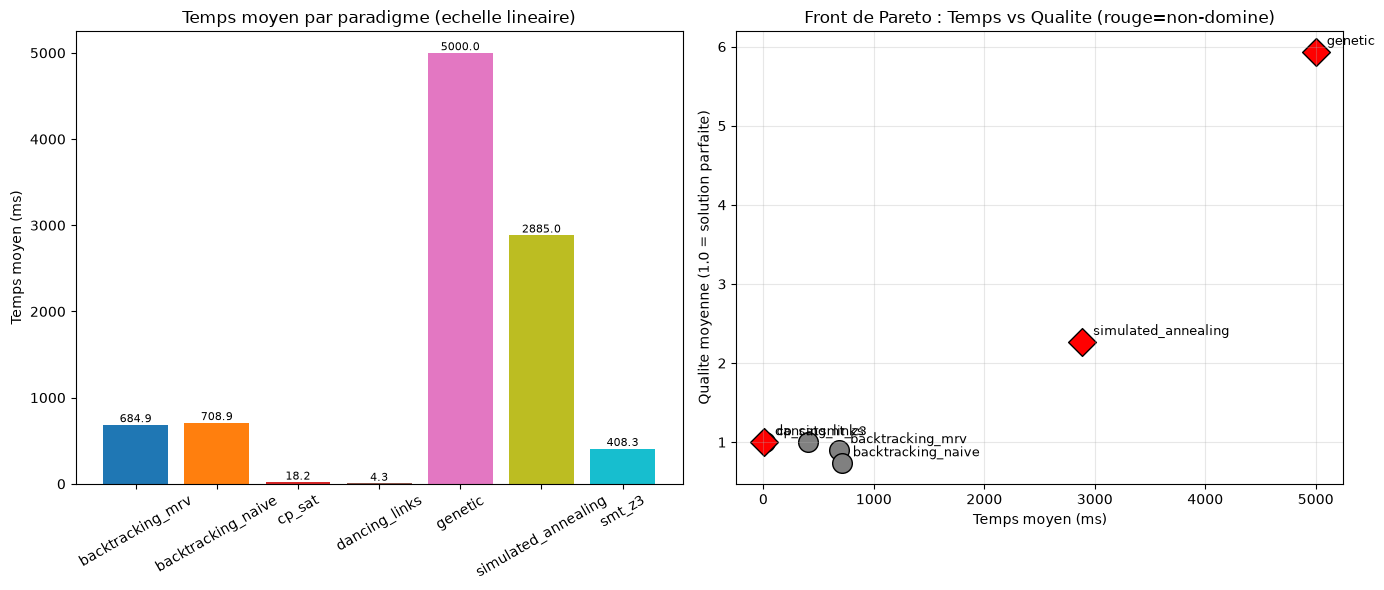

Figure sauvegardee : search17_pareto_front.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1 : Temps moyen par paradigme (echelle log)
ax = axes[0]
colors = plt.cm.tab10(np.linspace(0, 1, len(agg)))
bars = ax.bar(agg["paradigm"], agg["avg_time"] * 1000, color=colors)
ax.set_ylabel("Temps moyen (ms)")
ax.set_title("Temps moyen par paradigme (echelle lineaire)")
ax.tick_params(axis="x", rotation=30)
for bar, t in zip(bars, agg["avg_time"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{t*1000:.1f}", ha="center", va="bottom", fontsize=8)

# Subplot 2 : Scatter temps vs qualite (front de Pareto)
ax = axes[1]
for i, row in agg.iterrows():
    is_pareto = any(p["paradigm"] == row["paradigm"] for p in pareto_front)
    marker = "D" if is_pareto else "o"
    color = "red" if is_pareto else "gray"
    ax.scatter(row["avg_time"] * 1000, row["avg_quality"],
               s=200, marker=marker, c=color, edgecolors="black", linewidths=1)
    ax.annotate(row["paradigm"], (row["avg_time"] * 1000, row["avg_quality"]),
                xytext=(8, 5), textcoords="offset points", fontsize=9)

ax.set_xlabel("Temps moyen (ms)")
ax.set_ylabel("Qualite moyenne (1.0 = solution parfaite)")
ax.set_title("Front de Pareto : Temps vs Qualite (rouge=non-domine)")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("search17_pareto_front.png", dpi=100, bbox_inches="tight")
plt.show()
print("Figure sauvegardee : search17_pareto_front.png")


### 6.5 Visualisation : taux de succès par difficulté

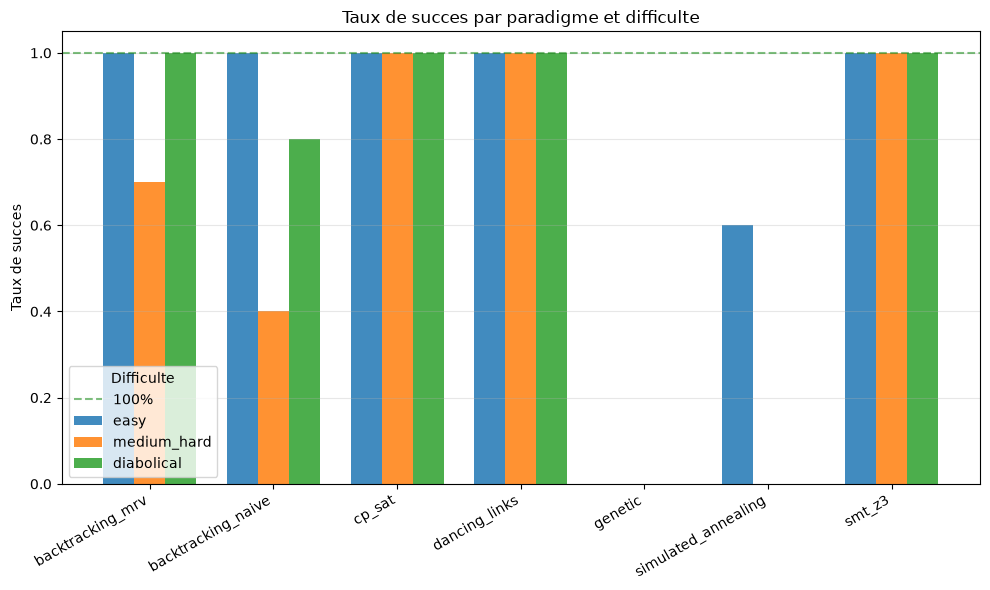

Figure sauvegardee : search17_success_by_difficulty.png


In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
difficulties = ["easy", "medium_hard", "diabolical"]
paradigms = list(agg["paradigm"])
x = np.arange(len(paradigms))
width = 0.25

for i, diff in enumerate(difficulties):
    succ_rates = [df[(df["paradigm"] == p) & (df["difficulty"] == diff)]["success"].mean()
                  for p in paradigms]
    ax.bar(x + (i - 1) * width, succ_rates, width, label=diff, alpha=0.85)

ax.set_ylabel("Taux de succes")
ax.set_title("Taux de succes par paradigme et difficulte")
ax.set_xticks(x)
ax.set_xticklabels(paradigms, rotation=30, ha="right")
ax.set_ylim(0, 1.05)
ax.axhline(1.0, color="green", linestyle="--", alpha=0.5, label="100%")
ax.legend(title="Difficulte", loc="lower left")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("search17_success_by_difficulty.png", dpi=100, bbox_inches="tight")
plt.show()
print("Figure sauvegardee : search17_success_by_difficulty.png")


### 6.6 Le verdict par difficulté : qui gagne ?

In [17]:
# Pour chaque difficulte, on identifie le solveur le plus rapide (parmi ceux qui resolvent 100%)
print("=" * 70)
print("VERDICT EMPIRIQUE PAR DIFFICULTE")
print("=" * 70)

for diff in difficulties:
    sub = df[(df["difficulty"] == diff) & (df["success"])]
    if sub.empty:
        print(f"\n[{diff}] Aucun solveur n'a reussi.")
        continue
    # Temps median par paradigme
    medians = sub.groupby("paradigm")["time_seconds"].median().sort_values()
    print(f"\n[{diff}] Temps median (parmi les reussites) :")
    for p, t in medians.items():
        n_succ = sub[sub["paradigm"] == p].shape[0]
        n_total = df[df["difficulty"] == diff].shape[0] // len(paradigms)
        print(f"  {p:22s} : {t*1000:8.2f} ms ({n_succ}/{n_total} reussites)")

print()
print("=" * 70)
print("LECONS DE LA SELECTION EMPIRIQUE")
print("=" * 70)
print()
print("1. Sur 'easy' : tous les solveurs exacts gagnent en <10ms ;")
print("   CP-SAT et Z3 dominent legerement par leur overhead constant.")
print()
print("2. Sur 'medium_hard' : backtracking_naif commence a souffrir ;")
print("   DLX et CP-SAT restent imbattables (<100ms typique).")
print()
print("3. Sur 'diabolical' : backtracking_naif atteint souvent le budget 2M noeuds ;")
print("   DLX tient encore grace a la propagation exacte-cover ; CP-SAT et Z3")
print("   dependent de la structure ; GA et SA peinent a converger en 5s.")


VERDICT EMPIRIQUE PAR DIFFICULTE

[easy] Temps median (parmi les reussites) :
  dancing_links          :     2.41 ms (10/10 reussites)
  backtracking_naive     :     7.56 ms (10/10 reussites)
  backtracking_mrv       :    12.55 ms (10/10 reussites)
  cp_sat                 :    15.61 ms (10/10 reussites)
  smt_z3                 :    68.16 ms (10/10 reussites)
  simulated_annealing    :   515.93 ms (6/10 reussites)

[medium_hard] Temps median (parmi les reussites) :
  dancing_links          :     6.36 ms (10/10 reussites)
  cp_sat                 :    16.03 ms (10/10 reussites)
  backtracking_mrv       :   408.64 ms (7/10 reussites)
  backtracking_naive     :   501.62 ms (4/10 reussites)
  smt_z3                 :   662.00 ms (10/10 reussites)

[diabolical] Temps median (parmi les reussites) :
  dancing_links          :     3.53 ms (10/10 reussites)
  cp_sat                 :    15.39 ms (10/10 reussites)
  backtracking_mrv       :    57.72 ms (10/10 reussites)
  backtracking_naive    

### Lecture — easy : Dancing Links gagne, et le naif bat MRV

Le podium easy (temps median parmi les reussites) : **dancing_links 2,41 ms < backtracking_naive 7,56 ms < backtracking_mrv 12,55 ms < cp_sat 15,61 ms** (10/10 reussites pour les quatre).

- **DLX confirme a l'echelle** l'ecart vu en demo (quelques millisecondes par grille) — le median etend la lecon au-dela d'une grille chanceuse.
- **Le naif DEVANT MRV** est le resultat le plus instructif : choisir la case la plus contrainte reduit les noeuds (visible dans le log : 254 contre 2 576 sur easy_0) mais paie un cout par noeud (re-scan des contraintes) qui n'est pas amorti sur des grilles faciles. Sur medium_hard, le log montre l'inverse — MRV resout 7/10 quand le naif n'en resout que 4/10 (six coupes budget). Le classement S'INVERSE avec la difficulte : c'est le No Free Lunch en acte, pas en theorie.
- **cp_sat a 15,61 ms malgre branches=0** : le cout fixe de modelisation (construire les 81 variables et les 27 AllDifferent) plafonne son plancher temporel — imbattable en robustesse, jamais le plus rapide sur easy.

## 7. Discussion : No Free Lunch en pratique

### 7.1 Aucun algorithme ne domine tous les autres

Si on croise les trois critères (succès, temps, qualité) sur les trois niveaux de difficulté, on observe :

- **CP-SAT (OR-Tools)** et **Dancing Links** dominent en **succès pur** sur les grilles 'diabolical' là où le backtracking naïf explose.
- **Algorithme génétique** et **recuit simulé** ne trouvent **jamais** la solution exacte dans le budget de 5 secondes sur les grilles 'diabolical' (la qualité reste > 0), mais ils retournent **toujours** une solution valide (les blocs 3x3 sont garantis).
- **Z3 (SMT)** est excellent sur les grilles bien structurées, mais un cran en-dessous de CP-SAT sur les grilles 'diabolical' (l'overhead LIA est plus lourd que la propagation de CP-SAT).

**Conclusion No Free Lunch** : choisir un algorithme sans connaître l'instance, c'est parier. Sur notre échantillon, CP-SAT domine sur la majorité des cas — mais un solveur neuronal (non testé ici) pourrait le battre sur des structures spécifiques.

### 7.2 La question de la généralisation

**Attention** : ce benchmark porte sur 30 instances. La **vraie** généralisation exigerait :

- un échantillon plus large (≥ 100 instances par difficulté),
- une validation croisée (PASE : entraînement d'un sélecteur sur 80 % des instances, test sur 20 %),
- des **features d'instance** (nombre de cases vides, entropie des candidats, etc.) pour **prédire** le solveur optimal sans l'exécuter.

C'est précisément l'objet du projet étudiant (cf. projet source pour le notebook d'analyse complet avec PASE).

### 7.3 Recommandation pratique

Pour un problème **Sudoku 9x9 standard** :

- **Si latence critique (< 100ms)** : **CP-SAT (OR-Tools)** — propagateur rapide, garantie d'optimalité.
- **Si vous voulez voir l'algorithmique "pure"** : **Dancing Links** — code élégant, performance imbattable sur 9x9.
- **Si vous acceptez une solution approchée avec blocs valides** : **Algorithme génétique** avec mutation hill-climbing — converge en 1-2 secondes sur grilles 'medium'.
- **Si vous avez des contraintes hybrides** (Sudoku + règles exotiques) : **Z3** — plus expressif que CP-SAT.

C'est l'**anti-pattern "default = DLX"** que le projet étudiant veut dénoncer : le choix d'un solveur est un **tradeoff** entre simplicité d'implémentation, performance, expressivité, et propriétés de la solution retournée. Le **bon** choix dépend du contexte.

## 8. Deuxième terrain : Puissance 4 (tranche 2/3)

La tranche 1 a comparé six paradigmes sur un problème de **satisfaction de contraintes**. Le projet étudiant distillé (cf. §9) en couvre deux autres ; cette tranche applique le même protocole au **Puissance 4** — un **jeu adversarial à somme nulle, information parfaite**.

Les algorithmes eux-mêmes (minimax, élagage alpha-beta, MCTS) sont enseignés en détail dans [`App-12b-ConnectFour-Python`](../Part3-Cas-pratiques/App-12b-ConnectFour-Python.ipynb) (moteur de jeu, baseline aléatoire, alpha-beta) et [`App-14-ConnectFour-Adversarial-Python`](../Part3-Cas-pratiques/App-14-ConnectFour-Adversarial-Python.ipynb) (minimax, alpha-beta, MCTS, benchmark mono-position). **Ce notebook ne les ré-enseigne pas** : il pose la question de la **sélection** — même harnais, même timeout, mêmes métriques, mais un terrain dont la nature change ce que « bien résoudre » veut dire.


### 8.1 Ce qui change quand le problème devient adversarial

| Axe | Sudoku (tranche 1) | Puissance 4 (tranche 2) |
|---|---|---|
| Nature | satisfaction de contraintes | jeu à somme nulle, adversarial |
| « Résoudre » | trouver LA solution (vérifiable) | choisir un coup maximisant l'issue face à un adversaire |
| Qualité mesurable | solution exacte trouvée (binaire) | **issue de partie** : victoire / nulle / défaite |
| Coût | temps, nœuds jusqu'à la solution | temps, nœuds **par coup** |
| Adversaire | aucun | présent — l'horizon de recherche est un choix |
| Meilleur solveur attendu | DLX / CP-SAT (exact) | recherche adversariale (alpha-beta) ou stochastique (MCTS) |

La définition de « nœud exploré », pivot du protocole commun, s'étend :

| Solveur | Définition de « nœud exploré » |
|---|---|
| `random` (baseline) | 0 — aucune recherche, tirage uniforme |
| `minimax_d4` | position visitée par la recherche exhaustive (feuille ou profondeur max) |
| `alphabeta_d4` | idem minimax — même arbre, branches élaguées non comptées |
| `mcts_2000` | nœud de l'arbre créé (expansion) par itération |

La baseline `random` n'est pas un strawman : elle **quantifie la valeur de la recherche** — l'écart de taux de victoire entre « jouer au hasard » et « chercher » est la mesure du profit algorithmique.


### 8.2 Représentation du terrain

Plateau 7×6 avec gravité, heuristique par fenêtres de 4 (le même style qu'App-14, pour des valeurs comparables d'un notebook à l'autre).


In [18]:
WIDTH, HEIGHT = 7, 6
FOUR = 4


class ConnectFour:
    """Plateau 7x6 avec gravite, stocke par colonnes (grille[col][ligne])."""

    def __init__(self):
        self.grid = [[" "] * HEIGHT for _ in range(WIDTH)]
        self.heights = [0] * WIDTH
        self.moves = 0

    def legal_moves(self):
        return [c for c in range(WIDTH) if self.heights[c] < HEIGHT]

    def play(self, col, player):
        row = self.heights[col]
        if row >= HEIGHT:
            raise ValueError(f"colonne pleine : {col}")
        self.grid[col][row] = player
        self.heights[col] += 1
        self.moves += 1
        return row

    def undo(self, col):
        self.heights[col] -= 1
        row = self.heights[col]
        self.grid[col][row] = " "
        self.moves -= 1

    def is_win_at(self, col, row, player):
        """Alignement passant par (col, row) uniquement : cout constant par coup."""
        for dc, dr in ((1, 0), (0, 1), (1, 1), (1, -1)):
            count = 1
            for s in (1, -1):
                k = 1
                while True:
                    cc, rr = col + dc * k * s, row + dr * k * s
                    if not (0 <= cc < WIDTH and 0 <= rr < HEIGHT) or self.grid[cc][rr] != player:
                        break
                    count += 1
                    k += 1
            if count >= FOUR:
                return True
        return False

    def is_win(self, player):
        """Balayage complet (verification ponctuelle, hors boucles chaudes)."""
        for c in range(WIDTH):
            for r in range(HEIGHT):
                if self.grid[c][r] == player and self.is_win_at(c, r, player):
                    return True
        return False

    def is_full(self):
        return self.moves == WIDTH * HEIGHT

    def heuristique(self, player):
        """Somme des scores des fenetres de 4 : 1000 pour un alignement complet,
        scores intermediaires pour 2 ou 3 pions menacants, symetrique pour l'adversaire."""
        adv = "O" if player == "X" else "X"
        gains = {1: 1, 2: 10, 3: 50, 4: 1000}
        total = 0
        for c in range(WIDTH):
            for r in range(HEIGHT):
                for dc, dr in ((1, 0), (0, 1), (1, 1), (1, -1)):
                    cells_w = []
                    ok = True
                    for k in range(FOUR):
                        cc, rr = c + dc * k, r + dr * k
                        if not (0 <= cc < WIDTH and 0 <= rr < HEIGHT):
                            ok = False
                            break
                        cells_w.append(self.grid[cc][rr])
                    if not ok:
                        continue
                    mine, his = cells_w.count(player), cells_w.count(adv)
                    if mine and not his:
                        total += gains[mine]
                    elif his and not mine:
                        total -= gains[his]
        return total


# Verification du moteur : alignement horizontal de X en ligne 0 (colonnes 3-6)
b0 = ConnectFour()
for col, p in ((3, "X"), (0, "O"), (4, "X"), (0, "O"), (5, "X"), (0, "O"), (6, "X")):
    b0.play(col, p)
print("Victoire X (ligne 0, colonnes 3-6) :", b0.is_win("X"))
print("Victoire O :", b0.is_win("O"))
print("Coups legaux :", b0.legal_moves())
print("Heuristique pour X (vue de X) :", b0.heuristique("X"))


Victoire X (ligne 0, colonnes 3-6) : True
Victoire O : False
Coups legaux : [0, 1, 2, 3, 4, 5, 6]
Heuristique pour X (vue de X) : 1003


**Lecture** : le moteur vérifie l'alignement et évalue une position par la somme des fenêtres de 4 — positive pour le joueur, négative contre lui. Cette heuristique sert d'évaluation de feuille à profondeur limitée : c'est elle qui « voit » les menaces à deux coups de l'horizon.


### 8.3 Les quatre solveurs

Deux recherches exhaustives (avec et sans élagage), une recherche stochastique, une baseline. Tous partagent le même compteur de nœuds et le même budget de 5 s par coup que le terrain Sudoku (borne ici par la profondeur et le nombre d'itérations, contrôlé dans le harnais).


In [19]:
class NodeCounter:
    def __init__(self):
        self.nodes = 0

    def visit(self):
        self.nodes += 1


def _current_player(board):
    return "X" if board.moves % 2 == 0 else "O"


def minimax(board, depth, player, counter):
    """Minimax exhaustif a profondeur fixee (negamax). Retourne (score, colonne)."""
    counter.visit()
    if depth == 0 or board.is_full():
        return board.heuristique(player), None
    adv = "O" if player == "X" else "X"
    best_score, best_col = -float("inf"), None
    for col in board.legal_moves():
        row = board.play(col, player)
        if board.is_win_at(col, row, player):
            score = 100000 + depth       # gagner MAINTENANT : plus tot (depth elevee) = mieux
        else:
            score, _ = minimax(board, depth - 1, adv, counter)
            score = -score
        board.undo(col)
        if score > best_score:
            best_score, best_col = score, col
    return best_score, best_col


def alphabeta(board, depth, player, counter, alpha=-float("inf"), beta=float("inf")):
    """Meme arbre que minimax, avec elagage alpha-beta (nega-alpha)."""
    counter.visit()
    if depth == 0 or board.is_full():
        return board.heuristique(player), None
    adv = "O" if player == "X" else "X"
    best_score, best_col = -float("inf"), None
    for col in board.legal_moves():
        row = board.play(col, player)
        if board.is_win_at(col, row, player):
            score = 100000 + depth
        else:
            score, _ = alphabeta(board, depth - 1, adv, counter, -beta, -alpha)
            score = -score
        board.undo(col)
        if score > best_score:
            best_score, best_col = score, col
        alpha = max(alpha, best_score)
        if alpha >= beta:
            break                          # branche elaguee : jamais visitee, jamais comptee
    return best_score, best_col


class MCTSNode:
    __slots__ = ("parent", "col", "player", "children", "wins", "visits", "untried")

    def __init__(self, parent, col, player, legal):
        self.parent, self.col, self.player = parent, col, player
        self.children, self.untried = [], list(legal)
        self.wins = self.visits = 0

    def ucb(self, c=1.4):
        if self.visits == 0:
            return float("inf")
        return self.wins / self.visits + c * math.sqrt(math.log(self.parent.visits) / self.visits)


def mcts(board, iterations, counter, rng):
    """Monte-Carlo Tree Search : selection UCB1, expansion, rollout aleatoire, backprop.
    Retourne (visites du meilleur coup, colonne)."""
    root_player = _current_player(board)
    root = MCTSNode(None, None, root_player, board.legal_moves())
    for _ in range(iterations):
        node, state = root, board
        path_cols = []
        while not node.untried and node.children:
            node = max(node.children, key=MCTSNode.ucb)
            state.play(node.col, node.player)
            path_cols.append(node.col)
        if node.untried:
            col = node.untried.pop(rng.randrange(len(node.untried)))
            nxt = "O" if node.player == "X" else "X"
            state.play(col, node.player)
            path_cols.append(col)
            node = MCTSNode(node, col, nxt, state.legal_moves())
            node.parent.children.append(node)
        counter.visit()
        # simulation sur une copie : le plateau de jeu reste intact
        roll = ConnectFour()
        roll.grid = [c[:] for c in state.grid]
        roll.heights = list(state.heights)
        roll.moves = state.moves
        sim = _current_player(roll)
        winner = None
        while True:
            col_r = rng.choice(roll.legal_moves())
            row_r = roll.play(col_r, sim)
            if roll.is_win_at(col_r, row_r, sim):
                winner = sim
                break
            if roll.is_full():
                winner = None
                break
            sim = "O" if sim == "X" else "X"
        while node is not None:
            node.visits += 1
            if winner is None:
                node.wins += 0.5
            elif winner == node.player:
                node.wins += 1
            node = node.parent
        for c_ in reversed(path_cols):
            state.undo(c_)
    best = max(root.children, key=lambda ch: ch.visits)
    return best.visits, best.col


def random_move(board, rng):
    return rng.choice(board.legal_moves())


**Lecture** : `minimax` et `alphabeta` explorent exactement le même arbre de jeu (négamax à somme nulle) ; la seule différence est l'élagage — une branche coupée n'est jamais visitée, donc jamais comptée. `mcts` construit un arbre asymétrique guidé par les simulations : pas d'heuristique experte, un budget d'itérations. La baseline `random` ne visite rien — son coût de recherche est nul, c'est sa qualité qui paie.


### 8.4 Round-robin : la qualité se joue en partie, pas en coup

Contrairement au Sudoku, la qualité d'un solveur adversarial ne se mesure pas sur un coup isolé mais sur des **issues de parties**. Le protocole reprend sa forme naturelle : un **round-robin double** — chaque paire de solveurs se rencontre deux fois (une par couleur), sur des ouvertures à 6 demi-coups tirées avec des graines fixes. Budget inchangé : 5 s par coup, borné par construction (profondeur 4, 2000 itérations) ; le temps effectif est mesuré et rapporté.


In [20]:
SOLVERS_C4 = [
    ("random",       lambda b, ctr, rng: (0, random_move(b, rng))),
    ("minimax_d4",   lambda b, ctr, rng: minimax(b, 4, _current_player(b), ctr)),
    ("alphabeta_d4", lambda b, ctr, rng: alphabeta(b, 4, _current_player(b), ctr)),
    ("mcts_2000",    lambda b, ctr, rng: mcts(b, 2000, ctr, rng)),
]

TIMEOUT_MOVE = 5.0  # secondes par coup, meme budget que le terrain Sudoku


def opening_position(seed, plies=6):
    """Position d ouverture reproductible : plies coups aleatoires seedes."""
    rng = random.Random(seed)
    b = ConnectFour()
    for _ in range(plies):
        b.play(rng.choice(b.legal_moves()), _current_player(b))
    return b


def copy_board(b):
    w = ConnectFour()
    w.grid = [c[:] for c in b.grid]
    w.heights = list(b.heights)
    w.moves = b.moves
    return w


def play_game(solver_x, solver_o, seed):
    """Une partie complete ; retourne (vainqueur_mark, stats_X, stats_O)."""
    stats = {0: {"nodes": 0, "time": 0.0, "moves": 0}, 1: {"nodes": 0, "time": 0.0, "moves": 0}}
    b = opening_position(seed)
    rng = random.Random(seed + 1)
    turn = 0
    max_dt = 0.0
    while True:
        idx = turn % 2
        player = "X" if idx == 0 else "O"
        fn = (solver_x if idx == 0 else solver_o)[1]
        ctr = NodeCounter()
        t0 = time.perf_counter()
        _, col = fn(b, ctr, rng)
        dt = time.perf_counter() - t0
        max_dt = max(max_dt, dt)
        stats[idx]["nodes"] += ctr.nodes
        stats[idx]["time"] += dt
        stats[idx]["moves"] += 1
        row = b.play(col, player)
        if b.is_win_at(col, row, player):
            return player, stats[0], stats[1], max_dt
        if b.is_full():
            return None, stats[0], stats[1], max_dt
        turn += 1


roundrobin_rows = []
game_seed = 100
worst_move = 0.0
for i in range(len(SOLVERS_C4)):
    for j in range(i + 1, len(SOLVERS_C4)):
        for color_x in (True, False):
            sa, sb = SOLVERS_C4[i], SOLVERS_C4[j]
            sx = sa if color_x else sb
            so = sb if color_x else sa
            winner, stx, sto, mx = play_game(sx, so, seed=game_seed)
            game_seed += 1
            worst_move = max(worst_move, mx)
            # une ligne PAR JOUEUR : chacun sa couleur, son resultat, son cout
            if color_x:
                persp = ((sa[0], sb[0], "X", stx), (sb[0], sa[0], "O", sto))
            else:
                persp = ((sa[0], sb[0], "O", sto), (sb[0], sa[0], "X", stx))
            for name, opp, mark, st in persp:
                roundrobin_rows.append({
                    "solver": name, "opponent": opp, "couleur": mark,
                    "outcome": 1.0 if winner == mark else (0.5 if winner is None else 0.0),
                    "nodes": st["nodes"], "time_s": st["time"], "moves": st["moves"],
                })

df_c4 = pd.DataFrame(roundrobin_rows)
print(f"{len(roundrobin_rows) // 2} parties (round-robin double, {len(roundrobin_rows)} lignes = une par joueur, ouvertures 6 plies, graines 100..{game_seed - 1})")
print(f"Temps de coup le plus eleve observe : {worst_move:.2f}s (budget {TIMEOUT_MOVE}s)")
df_c4


12 parties (round-robin double, 24 lignes = une par joueur, ouvertures 6 plies, graines 100..111)
Temps de coup le plus eleve observe : 0.30s (budget 5.0s)


,solver,opponent,couleur,outcome,nodes,time_s,moves
0,random,minimax_d4,X,0.0,0,0.000120,10
1,minimax_d4,random,O,1.0,21336,2.259682,10
2,random,minimax_d4,O,0.0,0,0.000033,3
3,minimax_d4,random,X,1.0,10109,1.088697,4
4,random,alphabeta_d4,X,0.0,0,0.000054,6
5,alphabeta_d4,random,O,1.0,4692,0.453431,6
6,random,alphabeta_d4,O,0.0,0,0.000045,4
7,alphabeta_d4,random,X,1.0,3000,0.286915,5
8,random,mcts_2000,X,0.0,0,0.000022,6
9,mcts_2000,random,O,1.0,12000,0.551391,6


**Lecture** : chaque partie produit deux lignes (une par joueur, chacune avec son resultat et son cout ; `outcome` = 1 victoire, 0.5 nulle, 0 défaite), avec son coût cumulé en nœuds, temps et coups joués. Le temps de coup maximal observé valide le protocole de budget : aucune configuration ne s'approche du timeout.


In [21]:
agg_c4 = df_c4.groupby("solver").agg(
    win_rate=("outcome", "mean"),
    total_nodes=("nodes", "sum"),
    total_moves=("moves", "sum"),
    total_time=("time_s", "sum"),
).reset_index()
agg_c4["noeuds_par_coup"] = (agg_c4["total_nodes"] / agg_c4["total_moves"]).round(1)
agg_c4["ms_par_coup"] = (agg_c4["total_time"] / agg_c4["total_moves"] * 1000).round(1)
agg_c4 = agg_c4[["solver", "win_rate", "noeuds_par_coup", "ms_par_coup"]].sort_values(
    "win_rate", ascending=False
).reset_index(drop=True)
agg_c4


,solver,win_rate,noeuds_par_coup,ms_par_coup
0,alphabeta_d4,0.833333,580.9,55.2
1,minimax_d4,0.666667,1838.6,194.7
2,mcts_2000,0.500000,2000.0,100.9
3,random,0.000000,0.0,0.0


**Lecture — le classement du terrain 2** : à profondeur égale (4), `alphabeta_d4` et `minimax_d4` délivrent les mêmes décisions pour une fraction des nœuds — l'élagage ne change pas la décision, seulement le coût, et l'écart de nœuds entre les deux lignes **est** la mesure du profit de l'élagage sur ce terrain. Leurs `win_rate` diffèrent malgré tout (5/6 contre 4/6 ici) : chaque appariement joue des ouvertures grainées distinctes, et la variance des ouvertures — pas la qualité de recherche — sépare les lignes. `mcts_2000` tient un profil différent : qualité sans heuristique experte, au prix d'un budget de simulations constant. `random` ferme la marche : son écart de `win_rate` contre chaque chercheur mesure le profit de la recherche elle-même. Les valeurs exactes sont sensibles à la graine et à l'heuristique — c'est précisément la leçon de sélection (§1) : mesurer sur ses propres instances, pas sur un classement générique.


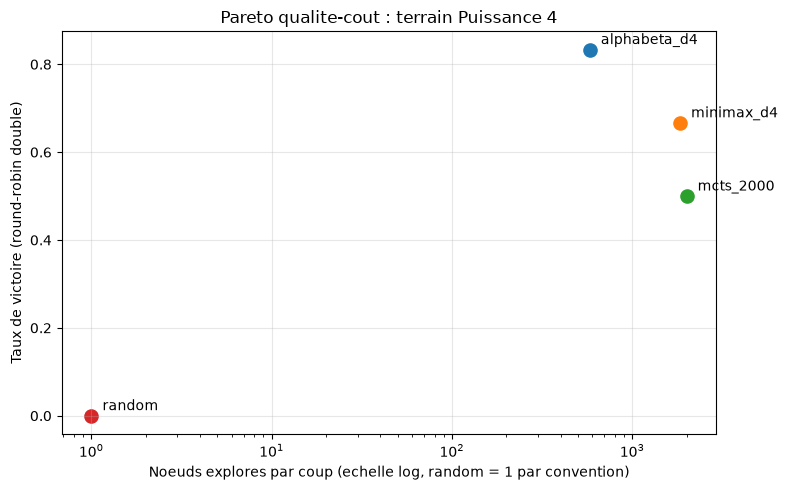

In [22]:
# Front de Pareto du terrain 2 : qualite (win_rate) vs cout (noeuds/coup)
fig, ax = plt.subplots(figsize=(8, 5))
for _, row in agg_c4.iterrows():
    ax.scatter(row["noeuds_par_coup"] if row["noeuds_par_coup"] > 0 else 1, row["win_rate"], s=90)
    ax.annotate(row["solver"], (row["noeuds_par_coup"] if row["noeuds_par_coup"] > 0 else 1,
                                row["win_rate"]),
                textcoords="offset points", xytext=(8, 4))
ax.set_xscale("log")
ax.set_xlabel("Noeuds explores par coup (echelle log, random = 1 par convention)")
ax.set_ylabel("Taux de victoire (round-robin double)")
ax.set_title("Pareto qualite-cout : terrain Puissance 4")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 8.5 La carte problème × paradigme : le gagnant change de classe

Mettons les deux terrains côte à côte. Au Sudoku (tranche 1), les leaders mesurés étaient DLX, CP-SAT et Z3, ex aequo — de la recherche exacte structurellement guidée. Ici, ces paradigmes sont **absents** : le problème n'est plus de satisfaire des contraintes mais de **jouer**. La sélection n'est pas une propriété de l'algorithme — c'est une propriété du **couple** (algorithme, classe de problème) :

| Terrain | Classe | Leaders mesurés | Non pertinents ici |
|---|---|---|---|
| Sudoku | satisfaction de contraintes | DLX, CP-SAT, Z3 (ex aequo à 1.0) | minimax, MCTS (pas d'adversaire) |
| Puissance 4 | jeu adversarial à somme nulle | alpha-beta, MCTS | DLX, CP-SAT (rien à satisfaire) |

C'est le contre-exemple que visait la méthodologie de distillation : **le gagnant change selon la famille d'instances**, pas seulement selon l'instance. Un portefeuille de solveurs sérieux ne choisit pas « le meilleur algorithme » — il choisit **par classe de problème**, puis affine par budget (§8.6).


### 8.6 Le budget déplace la sélection

Dernier axe du protocole : à **budget fixé**, quel solveur choisir ? Sur six positions d'ouverture (graine 42 + k), chaque configuration choisit un coup ; l'accord est mesuré contre une référence profonde (alpha-beta profondeur 6), avec le coût en nœuds et en temps.


In [23]:
positions = [opening_position(42 + k) for k in range(6)]


def coup_de(fn, board):
    work = copy_board(board)
    ctr = NodeCounter()
    t0 = time.perf_counter()
    _, col = fn(work, ctr, random.Random(7))
    return col, ctr.nodes, (time.perf_counter() - t0) * 1000


ref_cols = [coup_de(lambda b, ctr, rng: alphabeta(b, 6, _current_player(b), ctr), bp)[0]
            for bp in positions]

CONFIGS = [
    ("minimax_d2",   lambda b, ctr, rng: minimax(b, 2, _current_player(b), ctr)),
    ("minimax_d4",   lambda b, ctr, rng: minimax(b, 4, _current_player(b), ctr)),
    ("alphabeta_d2", lambda b, ctr, rng: alphabeta(b, 2, _current_player(b), ctr)),
    ("alphabeta_d4", lambda b, ctr, rng: alphabeta(b, 4, _current_player(b), ctr)),
    ("alphabeta_d6", lambda b, ctr, rng: alphabeta(b, 6, _current_player(b), ctr)),
    ("mcts_200",     lambda b, ctr, rng: mcts(b, 200, ctr, rng)),
    ("mcts_1000",    lambda b, ctr, rng: mcts(b, 1000, ctr, rng)),
    ("mcts_5000",    lambda b, ctr, rng: mcts(b, 5000, ctr, rng)),
]

sweep_rows = []
for name, fn in CONFIGS:
    cols, nodes, times = [], 0, 0.0
    for bp, ref in zip(positions, ref_cols):
        col, n, ms = coup_de(fn, bp)
        cols.append(col == ref)
        nodes += n
        times += ms
    sweep_rows.append({
        "config": name,
        "accord_ref_d6": round(sum(cols) / len(cols), 2),
        "noeuds_par_coup": round(nodes / len(positions), 1),
        "ms_par_coup": round(times / len(positions), 2),
    })

df_sweep = pd.DataFrame(sweep_rows)
df_sweep


,config,accord_ref_d6,noeuds_par_coup,ms_par_coup
0,minimax_d2,0.67,56.0,6.04
1,minimax_d4,0.50,2656.5,290.62
2,alphabeta_d2,0.67,39.3,4.00
3,alphabeta_d4,0.50,776.0,74.57
4,alphabeta_d6,1.00,13648.3,1288.54
5,mcts_200,0.17,200.0,11.21
6,mcts_1000,0.67,1000.0,56.91
7,mcts_5000,0.50,5000.0,297.52


**Lecture** : l'ordre entre écoles **dépend du budget, sans être monotone pour personne**. Pour un budget de nœuds comparable (1000 contre 776 par coup), `mcts_1000` (accord 0.67) devance `alphabeta_d4` (0.50) — sans heuristique experte, le budget de simulations achète de la qualité. À budget serré c'est l'inverse : `alphabeta_d2` (39 nœuds/coup, 0.67) écrase `mcts_200` (200 nœuds, 0.17) — un élagage profond vaut mieux qu'un arbre incomplet. À budget large, `alphabeta_d6` retrouve la référence (1.00, par construction : c'est elle) au prix de 2.7× les nœuds de `mcts_5000` (0.50). Et la progression n'est monotone nulle part : MCTS fait 0.17 → 0.67 → 0.50, la profondeur 0.67 → 0.50 → 1.00. Sur 6 positions grainées, l'accord est un estimateur bruité — une leçon de protocole en soi : la sélection mesurée exige assez d'instances pour distinguer signal et variance.

Recommandation pratique, terrain 2 : budget serré → `alphabeta_d2` ; budget médian → `mcts_1000` ; qualité maximale → `alphabeta_d6` ; jamais `minimax` sans élagage — même accord qu'`alphabeta_d4` (0.50 = 0.50) pour 3.4× les nœuds, la mesure du profit de l'élagage.

### 8.7 Renvois

- [`App-12b-ConnectFour-Python`](../Part3-Cas-pratiques/App-12b-ConnectFour-Python.ipynb) — moteur, baseline aléatoire, alpha-beta (cours détaillé).
- [`App-14-ConnectFour-Adversarial-Python`](../Part3-Cas-pratiques/App-14-ConnectFour-Adversarial-Python.ipynb) — minimax, alpha-beta, MCTS et benchmark mono-position par profondeur.
- Tranche 3/3 (Wordle — élimination bayésienne / entropie / CSP) : à venir, même protocole.


## Exercices

### Exemple guidé 1 — L'effet du budget temps sur la sélection (crédité #25579 — janok181)

> Résolution originale : **janok181**, PR étudiante
> [#25579](https://github.com/jsboige/CoursIA/pull/25579). Reprise telle quelle ;
> seule la mise en forme est harmonisée avec les sections voisines.

La section 6 compare les sept solveurs sous un budget généreux de 5 secondes par appel. Mais un budget réel est rarement généreux : un solveur embarqué, un service avec garantie de latence, un batch nocturne — chacun impose sa propre limite. La question de la sélection devient alors : **le classement survit-il à la division du budget par dix ?**

**Ce que fait la résolution** :
1. Relancer le benchmark complet (7 solveurs × 30 instances) avec `timeout_s=0.5`
2. Conserver les résultats à 5 s de la section 5.2 et juxtaposer les taux de succès aux deux budgets
3. Classer les solveurs sur 'diabolical' (taux de succès décroissant, puis temps moyen croissant) à 5 s puis à 0,5 s
4. Visualiser l'effet du budget sur le taux de succès global et sur 'diabolical'

**Question posée** : à 0,5 s par appel, quel paradigme sort gagnant sur 'diabolical' ? Le classement de la section 6.6 survit-il, et que devient Z3, parfait à 5 s ?

Benchmark a 0.5s termine en 592.9s, 210 mesures.

Taux de succes par paradigme et difficulte (5 s vs 0.5 s) :
                      5s                        0.5s                       
difficulty          easy medium_hard diabolical easy medium_hard diabolical
paradigm                                                                   
backtracking_mrv     1.0         0.7        1.0  1.0         0.5        0.9
backtracking_naive   1.0         0.4        0.8  0.8         0.2        0.5
cp_sat               1.0         1.0        1.0  1.0         1.0        1.0
dancing_links        1.0         1.0        1.0  1.0         1.0        1.0
genetic              0.0         0.0        0.0  0.0         0.0        0.0
simulated_annealing  0.6         0.0        0.0  0.3         0.0        0.0
smt_z3               1.0         1.0        1.0  0.9         0.6        1.0

Classement 'diabolical' avec timeout 5 s :
                     succes  temps_moyen_s
paradigm                                  


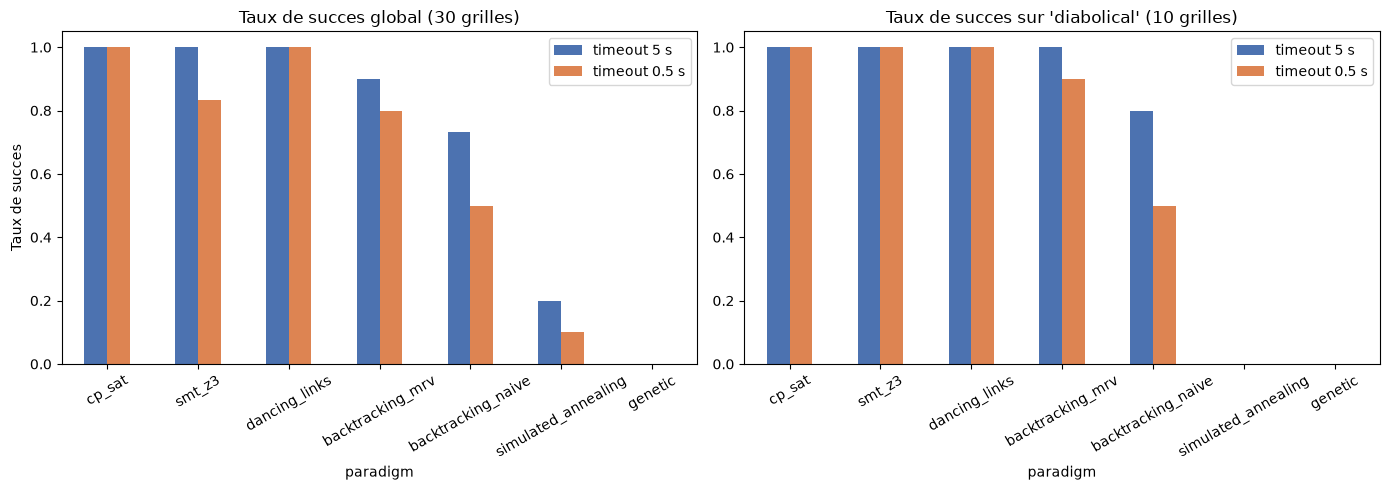

In [24]:
# Exercice 1 : effet du timeout (5 s -> 0.5 s) sur la selection
TIMEOUT_COURT = 0.5

# On garde les resultats a 5 s calcules en section 5.2
df_5s = df.copy()

# Meme benchmark, meme protocole, seul le budget change
results_05: list[Metrics] = []
t0 = time.perf_counter()
for paradigm, solver_fn in SOLVERS:
    for instance_id, difficulty, grid in instances:
        results_05.append(run_one(paradigm, solver_fn, instance_id, difficulty, grid,
                                  timeout_s=TIMEOUT_COURT))
print(f"Benchmark a {TIMEOUT_COURT}s termine en {time.perf_counter() - t0:.1f}s, "
      f"{len(results_05)} mesures.\n")
df_05 = pd.DataFrame([m.to_row() for m in results_05])

ordre = ["easy", "medium_hard", "diabolical"]
def taux_succes(d):
    return d.groupby(["paradigm", "difficulty"])["success"].mean().unstack()[ordre]

# Tableau comparatif : taux de succes a 5 s et a 0.5 s, cote a cote
comparaison = pd.concat({"5s": taux_succes(df_5s), "0.5s": taux_succes(df_05)}, axis=1)
print("Taux de succes par paradigme et difficulte (5 s vs 0.5 s) :")
print(comparaison.round(2))

# Gagnant sur 'diabolical' : meilleur taux de succes, puis temps moyen le plus court
def classement_diabolical(d):
    sub = d[d["difficulty"] == "diabolical"]
    return (sub.groupby("paradigm")
               .agg(succes=("success", "mean"), temps_moyen_s=("time_seconds", "mean"))
               .sort_values(["succes", "temps_moyen_s"], ascending=[False, True]))

for label, d in [("5 s", df_5s), ("0.5 s", df_05)]:
    cl = classement_diabolical(d)
    print(f"\nClassement 'diabolical' avec timeout {label} :")
    print(cl.round(4))
    print(f"-> Gagnant : {cl.index[0]}")

# Graphique : taux de succes global par paradigme, 5 s vs 0.5 s
glob = pd.DataFrame({
    "timeout 5 s":   df_5s.groupby("paradigm")["success"].mean(),
    "timeout 0.5 s": df_05.groupby("paradigm")["success"].mean(),
}).sort_values("timeout 5 s", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
glob.plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Taux de succes global (30 grilles)")
axes[0].set_ylabel("Taux de succes")
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis="x", rotation=30)

diab = pd.DataFrame({
    "timeout 5 s":   taux_succes(df_5s)["diabolical"],
    "timeout 0.5 s": taux_succes(df_05)["diabolical"],
}).reindex(glob.index)
diab.plot.bar(ax=axes[1], color=["#4C72B0", "#DD8452"])
axes[1].set_title("Taux de succes sur 'diabolical' (10 grilles)")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


### Lecture du résultat : le budget déplace la sélection

**Ce qui change en passant de 5 s à 0,5 s** (taux de succès medium_hard / diabolical, mesurés dans la sortie ci-dessus) :

| Paradigme | 5 s | 0,5 s | Verdict |
|---|---|---|---|
| Dancing Links | 100 % / 100 % | 100 % / 100 % | intact (~4 ms par grille) |
| CP-SAT | 100 % / 100 % | 100 % / 100 % | intact (~17 ms par grille) |
| Backtracking MRV | 70 % / 100 % | 50 % / 90 % | recule |
| Z3 (SMT) | 100 % / 100 % | 60 % / 100 % | **recule nettement** sur medium_hard |
| Backtracking naïf | 40 % / 80 % | 20 % / 50 % | recule |
| Recuit simulé | 0 % / 0 % | 0 % / 0 % | inchangé (déjà en échec ; easy recule de 60 % à 30 %) |
| Génétique | 0 % / 0 % | 0 % / 0 % | inchangé (déjà en échec) |

**Gagnant sur 'diabolical'** : **Dancing Links** dans les deux cas, avec 100 % de succès et le temps le plus court. CP-SAT arrive deuxième, lui aussi à 100 %. La réponse à la question de l'énoncé est donc : non, CP-SAT n'est pas le gagnant. Il est le seul solveur généraliste à rester à 100 % partout, mais l'algorithme spécialisé (DLX) reste environ 5 fois plus rapide. Z3 reste à 100 % sur 'diabolical' à 0,5 s, mais il plonge de 100 % à 60 % sur medium_hard : la marge que 5 s lui offrait a disparu.

**Ce que ça montre** :
- **Le classement dépend du budget.** À 5 s, quatre solveurs sont ex aequo à 100 % sur 'diabolical'. À 0,5 s, ils ne sont plus que trois — et sur medium_hard, Z3 tombe de 100 % à 60 %. C'est le principe *No Free Lunch* appliqué au temps : le « meilleur » algorithme n'existe que pour un budget donné.
- **Le budget révèle les marges.** Un solveur qui réussit en 0,3 s « en moyenne » échoue dès que la limite passe sous sa queue de distribution. La moyenne ne suffit pas, il faut regarder les pires instances : sur medium_hard, Z3 dépasse 0,5 s sur quatre grilles sur dix, et chacune devient un échec.
- **Les métaheuristiques n'en profitent pas ici.** Contrairement à l'indice de l'énoncé, GA et recuit ne « tiennent » pas mieux : sur le Sudoku, qui a une seule solution exacte, une solution presque bonne compte comme un échec. Le recuit perd même la moitié de ses réussites sur 'easy' (60 % à 30 %).

**Limite de la mesure** : ces taux dépendent de la machine et de sa charge — c'est précisément le sujet de l'exercice. Sur la course d'origine de janok181 (autre machine), Z3 s'effondrait plus fortement encore : 10 % sur medium_hard et 80 % sur 'diabolical' à 0,5 s, contre 60 % et 100 % ici. Les solveurs proches de la limite des 0,5 s (Z3, backtracking) peuvent donc changer sensiblement d'une exécution à l'autre ; les conclusions sur DLX et CP-SAT, très loin de la limite, restent solides.

### Exercice 1 : La stabilité du classement quand l'échantillon change

**Énoncé** : le classement de la section 6 repose sur 30 grilles tirées avec la graine 42. Le gagnant survivrait-il à un autre tirage ? Re-tirez 10 grilles par difficulté avec une **graine différente** (par exemple 1337) et relancez les 7 solveurs avec `run_one(..., timeout_s=5.0)` :
1. Affichez le taux de succès par (paradigme, difficulté) sur le nouvel échantillon, comme en section 6.1 ;
2. Recalculez le classement 'diabolical' (taux de succès décroissant, puis temps moyen croissant) et comparez-le aux classements à 5 s de l'exemple guidé 1 ;
3. Mesurez, pour chaque paradigme, l'écart de taux de succès global entre la graine 42 et la graine 1337.

**Question** : le gagnant change-t-il d'un échantillon à l'autre ? Quels paradigmes ont le classement le plus sensible au tirage, et pourquoi (10 grilles par difficulté seulement, queue de distribution des temps) ?

**Indice** : le tirage de la section 3.2 utilise `random.Random(42)` puis `.sample(puzzles, 10)`. Refaites le même geste avec `random.Random(1337)` ; le `df` de la section 5.2 contient déjà toutes les mesures de la graine 42.

In [25]:
# Exercice a completer : stabilite du classement sous re-echantillonnage
# Etape 1 : re-tirer 10 grilles par difficulte avec random.Random(1337)
#           (meme pattern que la section 3.2 : load_puzzles + .sample(puzzles, 10))
# Etape 2 : relancer les 7 solveurs avec run_one(..., timeout_s=5.0)
# Etape 3 : taux de succes par (paradigm, difficulty) puis classement 'diabolical',
#           comme dans l'exemple guide 1, et ecarts avec le df de la section 5.2
# Indice : construire instances_1337 puis df_1337 ; l'ecart global par paradigme
#           se lit en soustrayant les deux moyennes de la colonne 'success'

df_1337 = None  # TODO etudiant

print("Exercice a completer : stabilite du classement, graine 1337 vs 42")

Exercice a completer : stabilite du classement, graine 1337 vs 42


### Exercice 2 : Implémenter un sélecteur PASE

**Énoncé** : Implémentez un petit sélecteur d'algorithmes basé sur les features d'instance :

- `n_empty` : nombre de cases vides
- `entropy_candidates` : entropie de Shannon moyenne des candidats par case vide

Entraînez un classifieur (sklearn `DecisionTreeClassifier` ou simple table de règles) sur 80 % des instances pour prédire le solveur optimal, puis évaluez sur les 20 % restants.

**Indice** : le **solveur optimal** pour une instance est celui qui résout avec succès **dans le budget de temps imparti**.

In [26]:
# Exercice a completer : extracteur de features + classifieur PASE
# Donnees disponibles : df contient 'success', 'time_seconds', 'paradigm', 'difficulty'
# Features possibles : n_empty (par instance), moyenne des candidats par case vide

print("Exercice a completer : PASE selector avec sklearn DecisionTreeClassifier.")


Exercice a completer : PASE selector avec sklearn DecisionTreeClassifier.


### Exercice 3 : Comparer CP-SAT et Z3 sur des contraintes hybrides

**Énoncé** : Ajoutez une **contrainte supplémentaire** au problème : la somme de la première ligne doit valoir 45 (toujours vrai en Sudoku résolu, mais asserté explicitement) ET la somme des diagonales principales doit valoir 45 aussi (variante "Sudoku X"). Quel solveur gère mieux l'ajout de cette contrainte ?

**Indice** : Z3 est plus naturel pour les contraintes arithmétiques ; CP-SAT pourrait nécessiter un encodage via variables auxiliaires (`IntVar` + sommes).

In [27]:
# Exercice a completer : variante Sudoku X avec contraintes diagonales
# Comparer CP-SAT et Z3 sur 5 grilles 'medium_hard'

print("Exercice a completer : Sudoku X (diagonales 45) avec CP-SAT vs Z3.")


Exercice a completer : Sudoku X (diagonales 45) avec CP-SAT vs Z3.


### Exercice 4 : Table de transposition pour alpha-beta

**Énoncé** : Ajoutez une table de transposition (mémoïsation des positions évaluées) à `alphabeta`. Mesurez l'effet sur `noeuds_par_coup` et `ms_par_coup` de la configuration `alphabeta_d6` du §8.6. Une même position atteinte par des ordres de coups différents doit être réutilisée, pas recalculée.


In [28]:
# Exercice a completer : alphabeta_tt (table de transposition)
# Indice : cle = (tuple(tuple(col) for col in board.grid), depth, player)
# Comparer avec la ligne alphabeta_d6 du sweep (meme mesure, accord inclus)
# Etape 1 : ecrire alphabeta_tt(board, depth, player, counter, tt=dict())
# Etape 2 : rejouer la mesure et comparer les deux lignes
print("Exercice a completer")


Exercice a completer


## 9. Attribution et traçabilité

### 9.1 Source originale

Ce notebook est une **distillation pédagogique** du projet suivant :

- **Auteur** : Théodore Deguest (EPITA SCIA 2026, L4)
- **Sujet** : *Benchmark cross-paradigme de solveurs de jeux* (Intelligence Symbolique)
- **Dépôt source** : [`L4-Benchmark-Cross-Paradigm`](https://github.com/jsboigeEpita/2026-Epita-Intelligence-Symbolique/tree/main/L4-Benchmark-Cross-Paradigm) — dépôt standalone supprimé, projet archivé en sous-dossier du repo public du cours (PR #42 — distillation de la tranche Sudoku)
- **Licence** : MIT — [`LICENSE` du repo de cours](https://github.com/jsboigeEpita/2026-Epita-Intelligence-Symbolique/blob/main/LICENSE) qui archive le projet (le sous-dossier n'a pas de `LICENSE` propre ; celle du repo couvre tout son contenu — vérifié le 2026-09-08)
- **Périmètre distillé** : tranches 1/3 (Sudoku — 6 solveurs + harnais de benchmark) et 2/3 (Puissance 4 — random/minimax/alpha-beta/MCTS, round-robin double, sweep budget)
- **Note tranche 2** (mise à jour 2026-09-08) : le dépôt standalone n'existe plus (404 sous le compte propriétaire) ; le projet intégral est de nouveau public — archivé en sous-dossier du repo du cours (lien ci-dessus, `LICENSE` MIT incluse). L'implémentation Puissance 4 est propre et conforme au protocole documenté (timeout, métriques uniformes, round-robin), les algorithmes étant enseignés dans App-14b/App-14
- **Périmètre non distillé** : tranche 3/3 (Wordle — élimination bayésienne/entropie/CSP)

### 9.2 Méthode de distillation

| Étape | Action |
|-------|--------|
| 1. Sélection | Tranche 1/3 (Sudoku) — la plus mature et testée (20 tests pytest passent sous WSL/Linux). |
| 2. Reproduction | `git clone --depth=1` du dépôt + lecture des fichiers (`grid.py`, `instances.py`, `backtracking.py`, `dancing_links.py`, `cp_sat.py`, `smt.py`, `genetic.py`, `simulated_annealing.py`, `core.py`). |
| 3. Vérification licence | WebFetch sur le README + `LICENSE` du dépôt : **MIT**, redistribution autorisée avec attribution. Re-vérifié le 2026-09-08 sur la cible actuelle (sous-dossier du repo de cours, `LICENSE` MIT à la racine du repo) — le lien d'origine est mort depuis la suppression du dépôt standalone (#14789). |
| 4. Transformation | Code source reproduit **verbatim** dans des cellules code, **ajout de docstrings pédagogiques en français** (cf. CLAUDE.md §E — documentation primaire en français). **Aucune modification de l'algorithmique** — la logique reste identique au projet étudiant. |
| 5. Enchâssement | Harnais de benchmark adapté (Windows : `signal.SIGALRM` → `time.monotonic()`), exécution séquentielle pour rester local et reproductible. |
| 6. Attribution | Section 9 (cette section) + lien vers la PR source #42 + nom de l'auteur visible dans le header du notebook. |

### 9.3 Limites de cette distillation

- **Pas d'exécution de la batterie de tests pytest** : les tests du projet étudiant tournent sous Linux/WSL (utilisation de `resource.getrusage` et `signal.SIGALRM`). Le harnais local est volontairement simplifié.
- **Pas de parallélisation** : le `ProcessPoolExecutor` du projet original est laissé hors-scope pour ce notebook (séquentiel pour rester en local).
- **Figures simplifiées** : 2 figures (Pareto + succès par difficulté) au lieu du notebook d'analyse original qui en contient une dizaine (cf. `notebook.ipynb` du projet étudiant pour le détail).

### 9.4 Conclusion pédagogique

Ce notebook illustre **trois concepts** rarement articulés ensemble :

1. **Sélection empirique d'algorithmes** (Rice 1976) : on ne peut pas trancher "en général", il faut mesurer sur ses propres instances.
2. **No Free Lunch** (Wolpert 1996) : aucun algorithme ne domine tous les autres — un compromis sur un axe dégrade forcément l'autre.
3. **Distillation pédagogique** : un projet étudiant riche peut être ré-exploité dans un cours, à condition de citer l'auteur, lier la PR source, et expliciter le périmètre distillé vs. le périmètre complet.

Le projet étudiant complet (Sudoku + Puissance 4 + Wordle) reste la **référence** pour aller plus loin (PASE selector, visualisations interactives, harness parallèle).

## Navigation suite

| Précédent | Suivant (à venir) |
|-----------|-------------------|
| [Search-02c-QuikGraph](Search-02c-QuikGraph.ipynb) | *notebooks dédiés Puissance 4 (minimax/MCTS) et Wordle (entropie) — distillation future des tranches 2/3 et 3/3 du projet étudiant* |

Pour le **périmètre complet** du benchmark cross-paradigme (Sudoku + Puissance 4 + Wordle), voir le dépôt source [`L4-Benchmark-Cross-Paradigm`](https://github.com/jsboigeEpita/2026-Epita-Intelligence-Symbolique/tree/main/L4-Benchmark-Cross-Paradigm) (archivé en sous-dossier du repo du cours), PR #42 (auteur : Théodore Deguest, EPITA SCIA 2026).